# 时间规律、双层需求预测与模型比较

**模块负责人：陈宇涵；整合复核：马文博**

本 Notebook 复用 `src.temporal_analysis`、`src.demand_model`、`src.station_model` 和
`src.model_comparison`，展示时间规律、会员与车型偏好、全城预测、核心站点预测和误差比较。
运行全部单元格会重新训练已约定的模型并生成图表、统计表和离线报告。

输入是全组统一的 `clean_trips.csv`。历史数据日期用于分析和评价。
模型在自然周开始前一次预测未来 168 小时，验证选型与最终测试分开；调度情景不参与这里的评分。
请先安装 `requirements.txt`，选择 **Python (Pyclass)** 内核，重启并运行全部单元格。

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import subprocess
import pandas as pd
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
ROOT = next((p for p in (current, *current.parents)
             if (p / 'src/station_model.py').is_file()
             and (p / 'config/cleaning_rules.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 Pyclass 项目根目录或 notebooks 目录启动。')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp/matplotlib'))
os.environ['PYTHONIOENCODING'] = 'utf-8'

from src.data_cleaning import read_clean_data
from src.utils import set_plot_style
from src.demand_model import PHASES, build_hourly, features

REPORTS = ROOT / 'reports'
TABLES = REPORTS / 'tables'
FIGURES = REPORTS / 'figures'
LOGS = ROOT / 'tmp/notebook-execution'
LOGS.mkdir(parents=True, exist_ok=True)
print('中文字体：', set_plot_style())

def run_module(module):
    log = LOGS / f'02-{module}.log'
    with log.open('w', encoding='utf-8') as stream:
        result = subprocess.run([sys.executable, '-m', f'src.{module}'], cwd=ROOT,
                                stdout=stream, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(log.read_text(encoding='utf-8')[-5000:])
    print(f'{module}：重新计算与导出完成。')

def show_figure(relative, width=1000):
    path = FIGURES / relative
    assert path.is_file(), path
    display(Image(filename=str(path), width=width))

中文字体： Microsoft YaHei


## 1. 数据范围与时间统计

按出发时刻统计全城小时需求，保留缺站点但时间有效的订单。工作日与周末分别除以实际天数；
订单数不等于用户人数。全月 31 天补齐为 744 个小时，缺记录小时在确认日期覆盖后补 0。

In [2]:
source = ROOT / 'data/processed/clean_trips.csv'
original_hash = hashlib.sha256(source.read_bytes()).hexdigest()
trips = read_clean_data(source)
y = build_hourly(trips)
assert len(y) == 744 and int(y.sum()) == len(trips)
assert trips.ride_id.is_unique
display(pd.DataFrame([{'有效骑行': len(trips), '小时格': len(y),
                       '工作日天数': trips.loc[trips.weekday.lt(5), 'started_at'].dt.normalize().nunique(),
                       '周末天数': trips.loc[trips.weekday.ge(5), 'started_at'].dt.normalize().nunique()}]))
run_module('temporal_analysis')
validation = pd.read_csv(TABLES / 'temporal_validation_summary.csv')
assert validation['结果'].eq('通过').all()
print('时间与偏好统计核验通过：', len(validation))

,有效骑行,小时格,工作日天数,周末天数
0,233180,744,23,8


temporal_analysis：重新计算与导出完成。
时间与偏好统计核验通过： 46


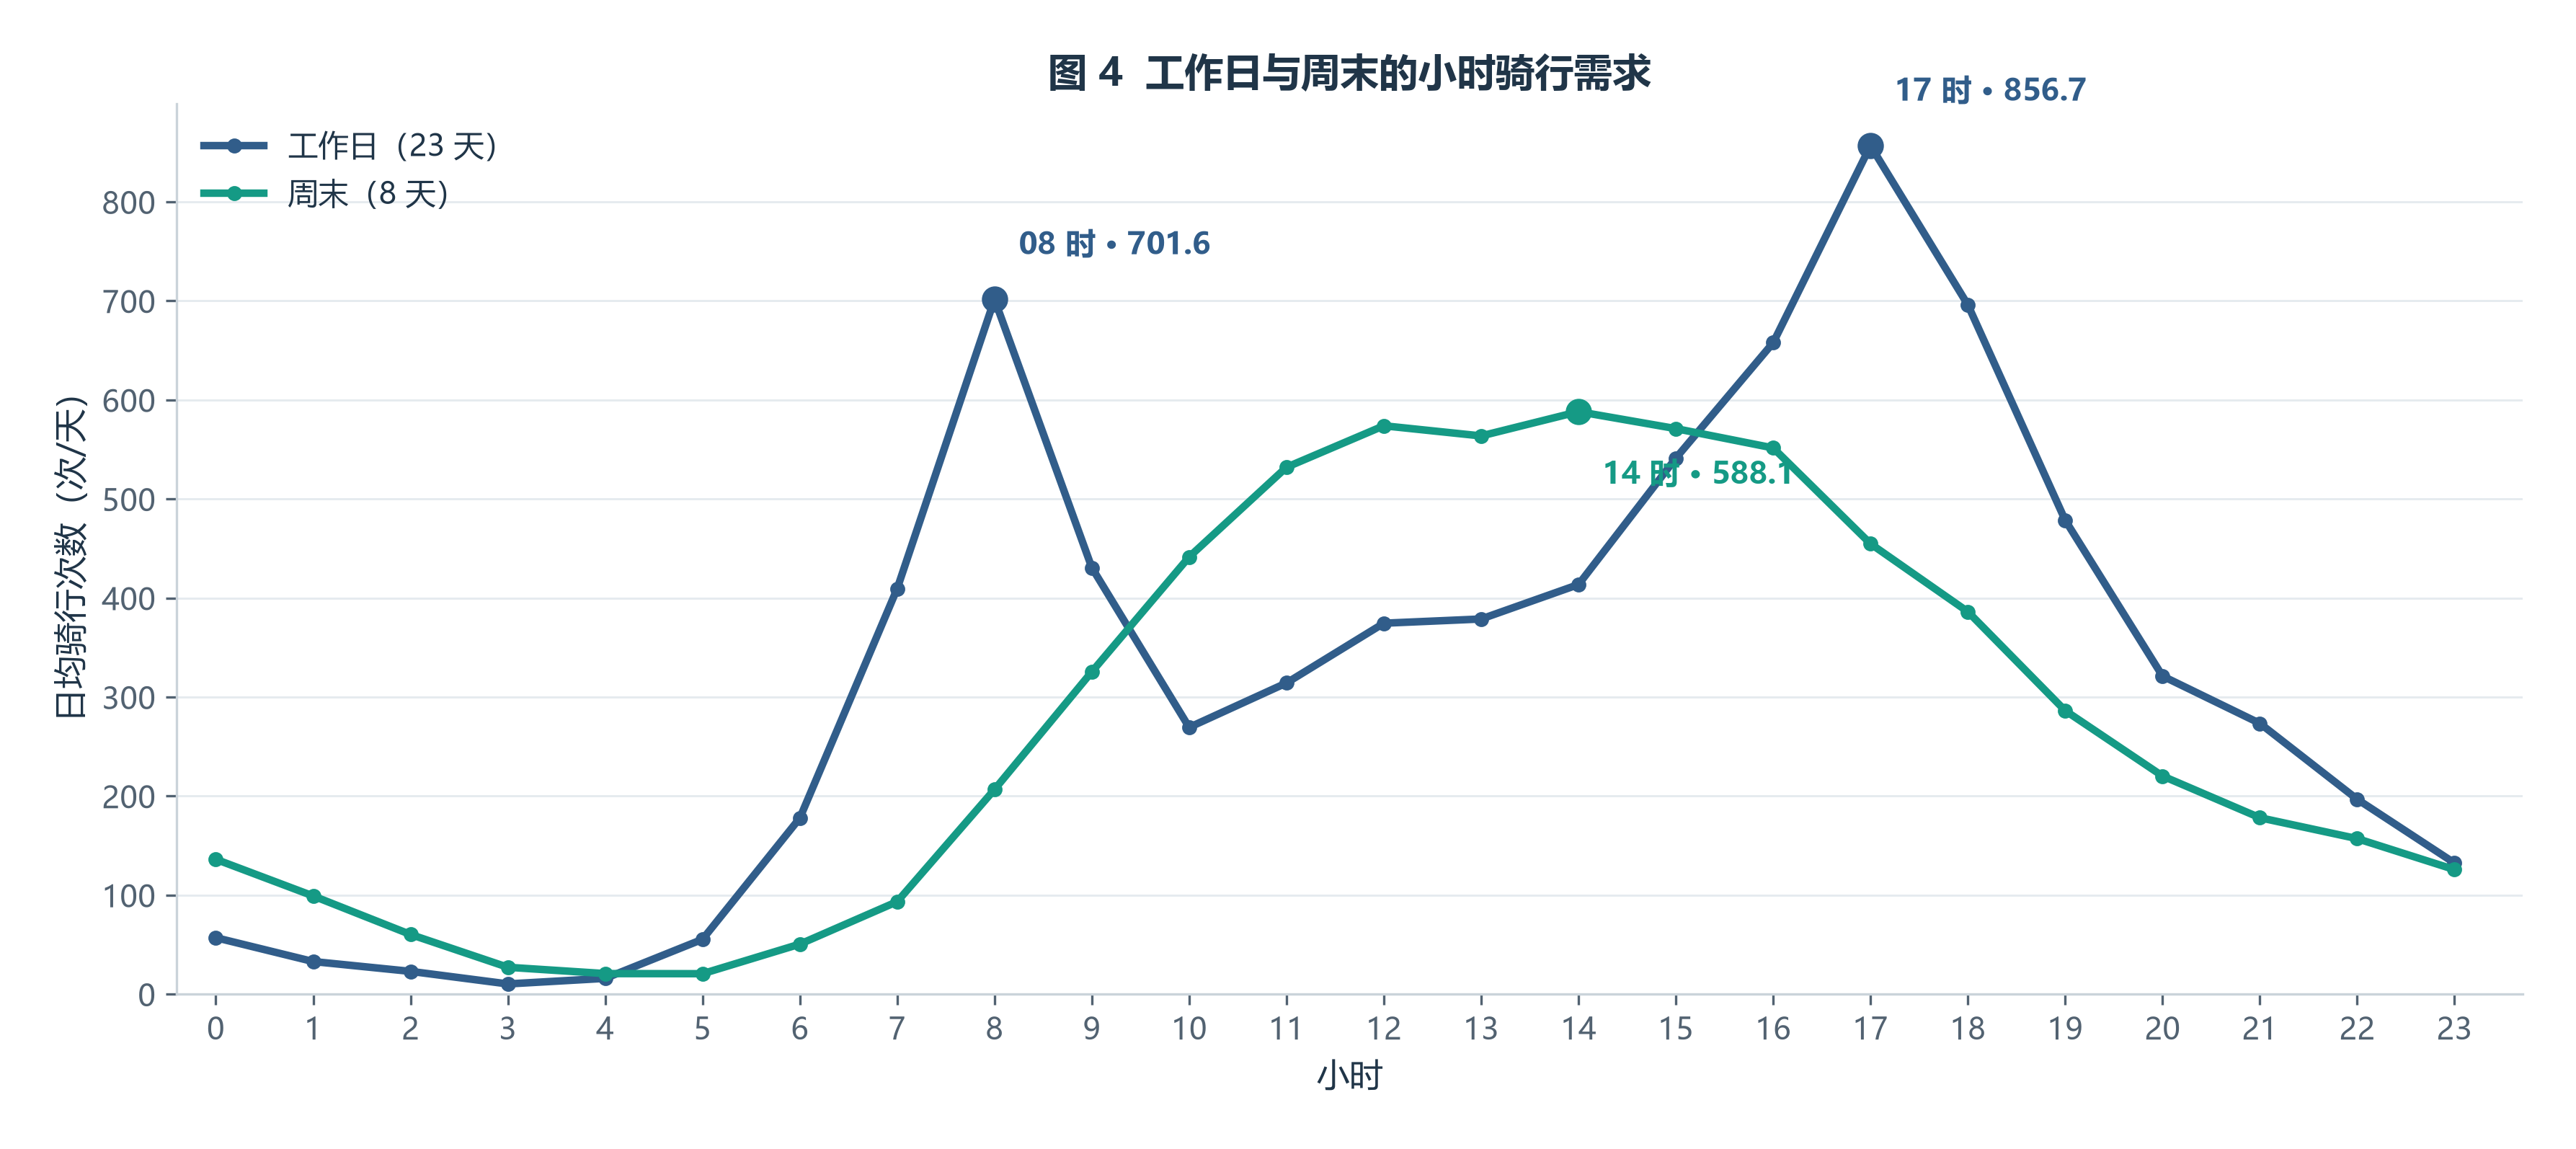

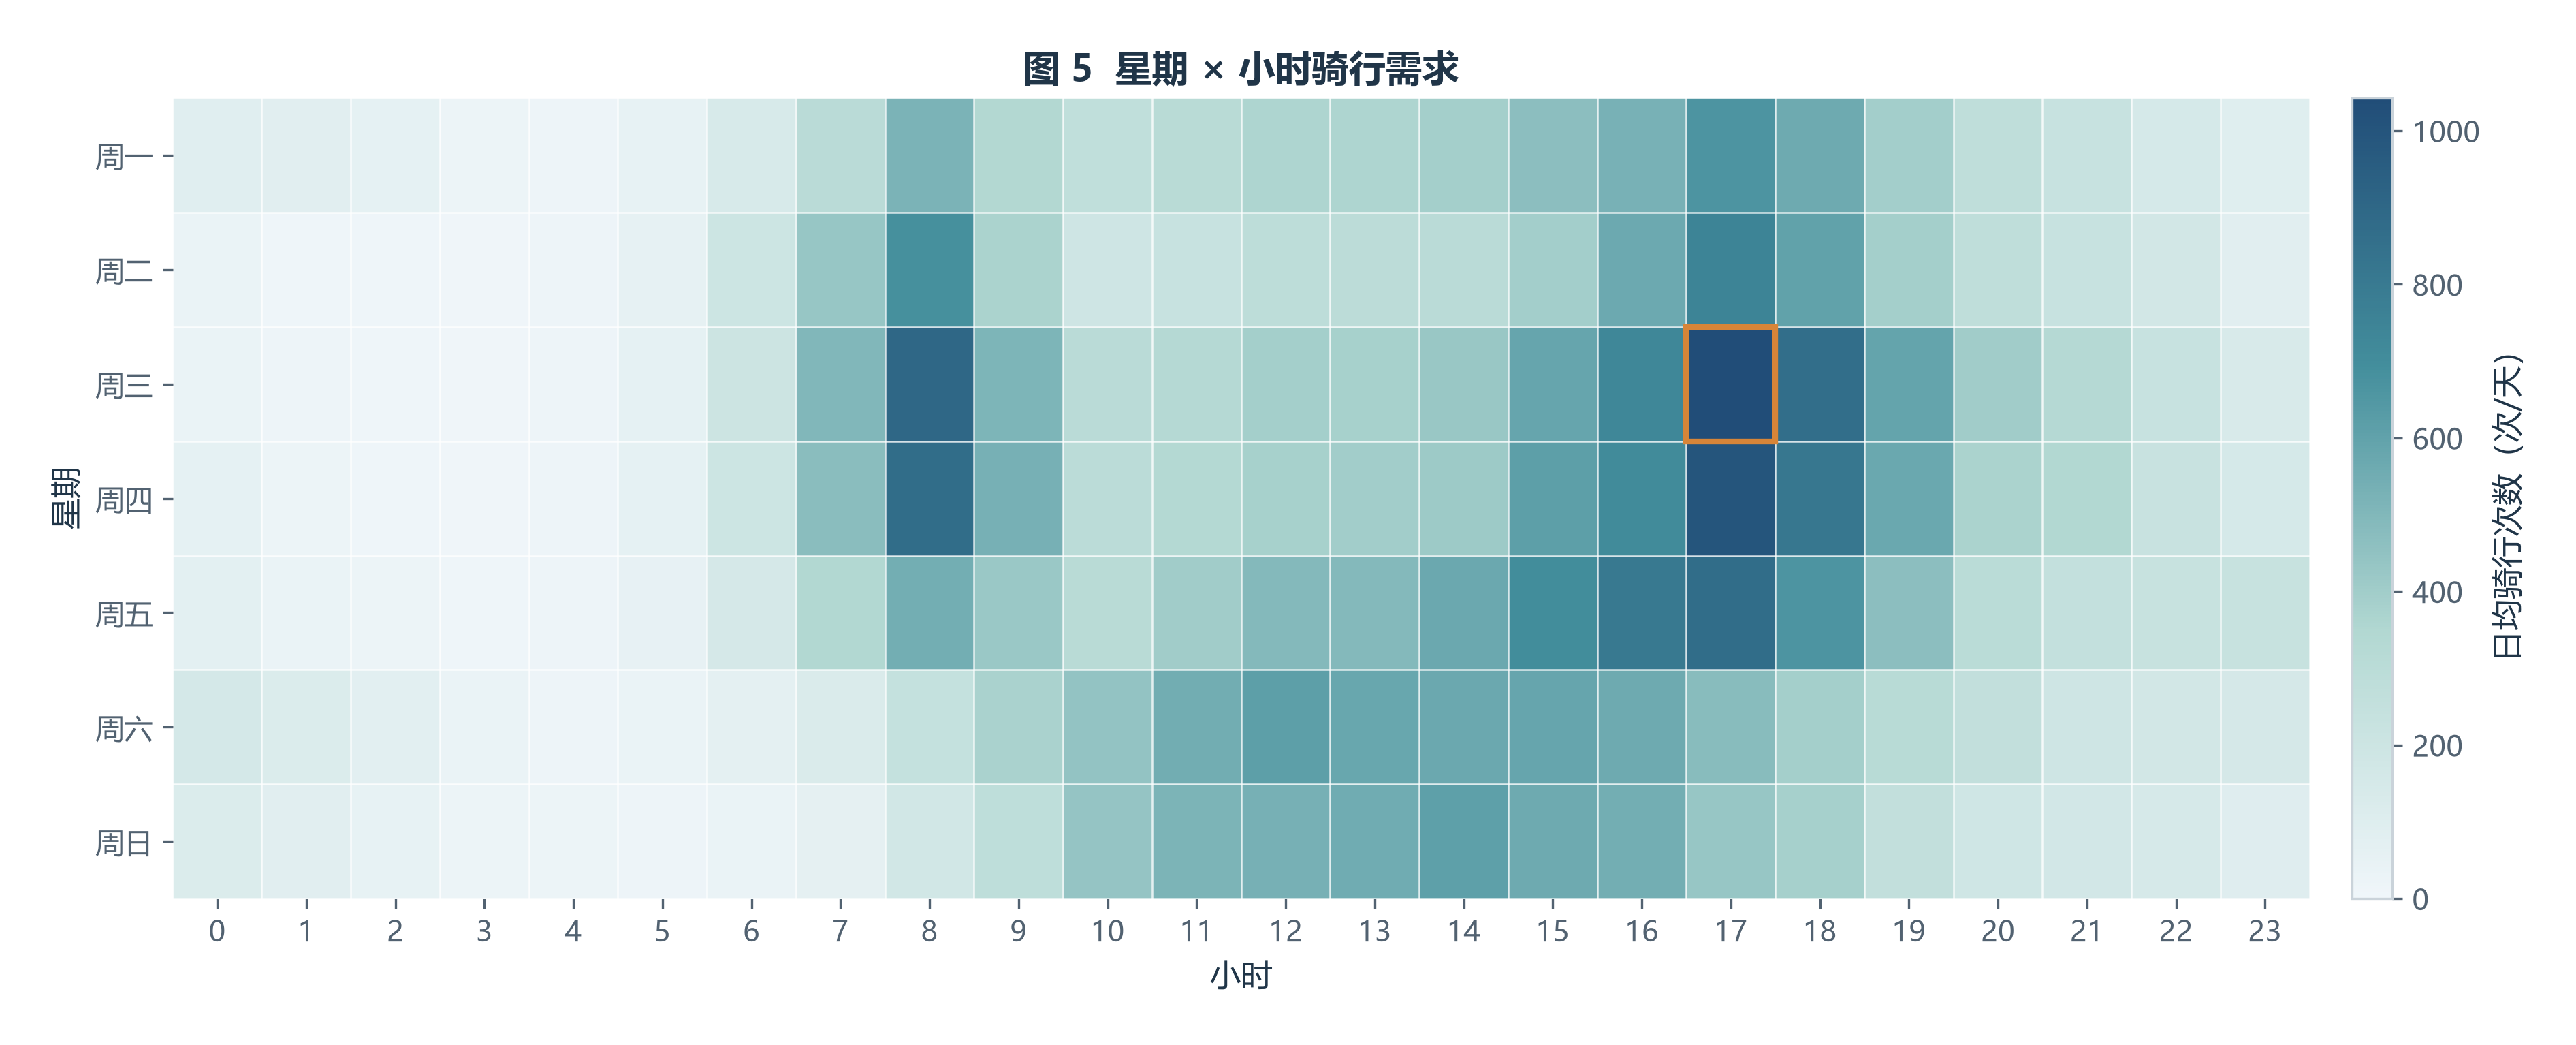

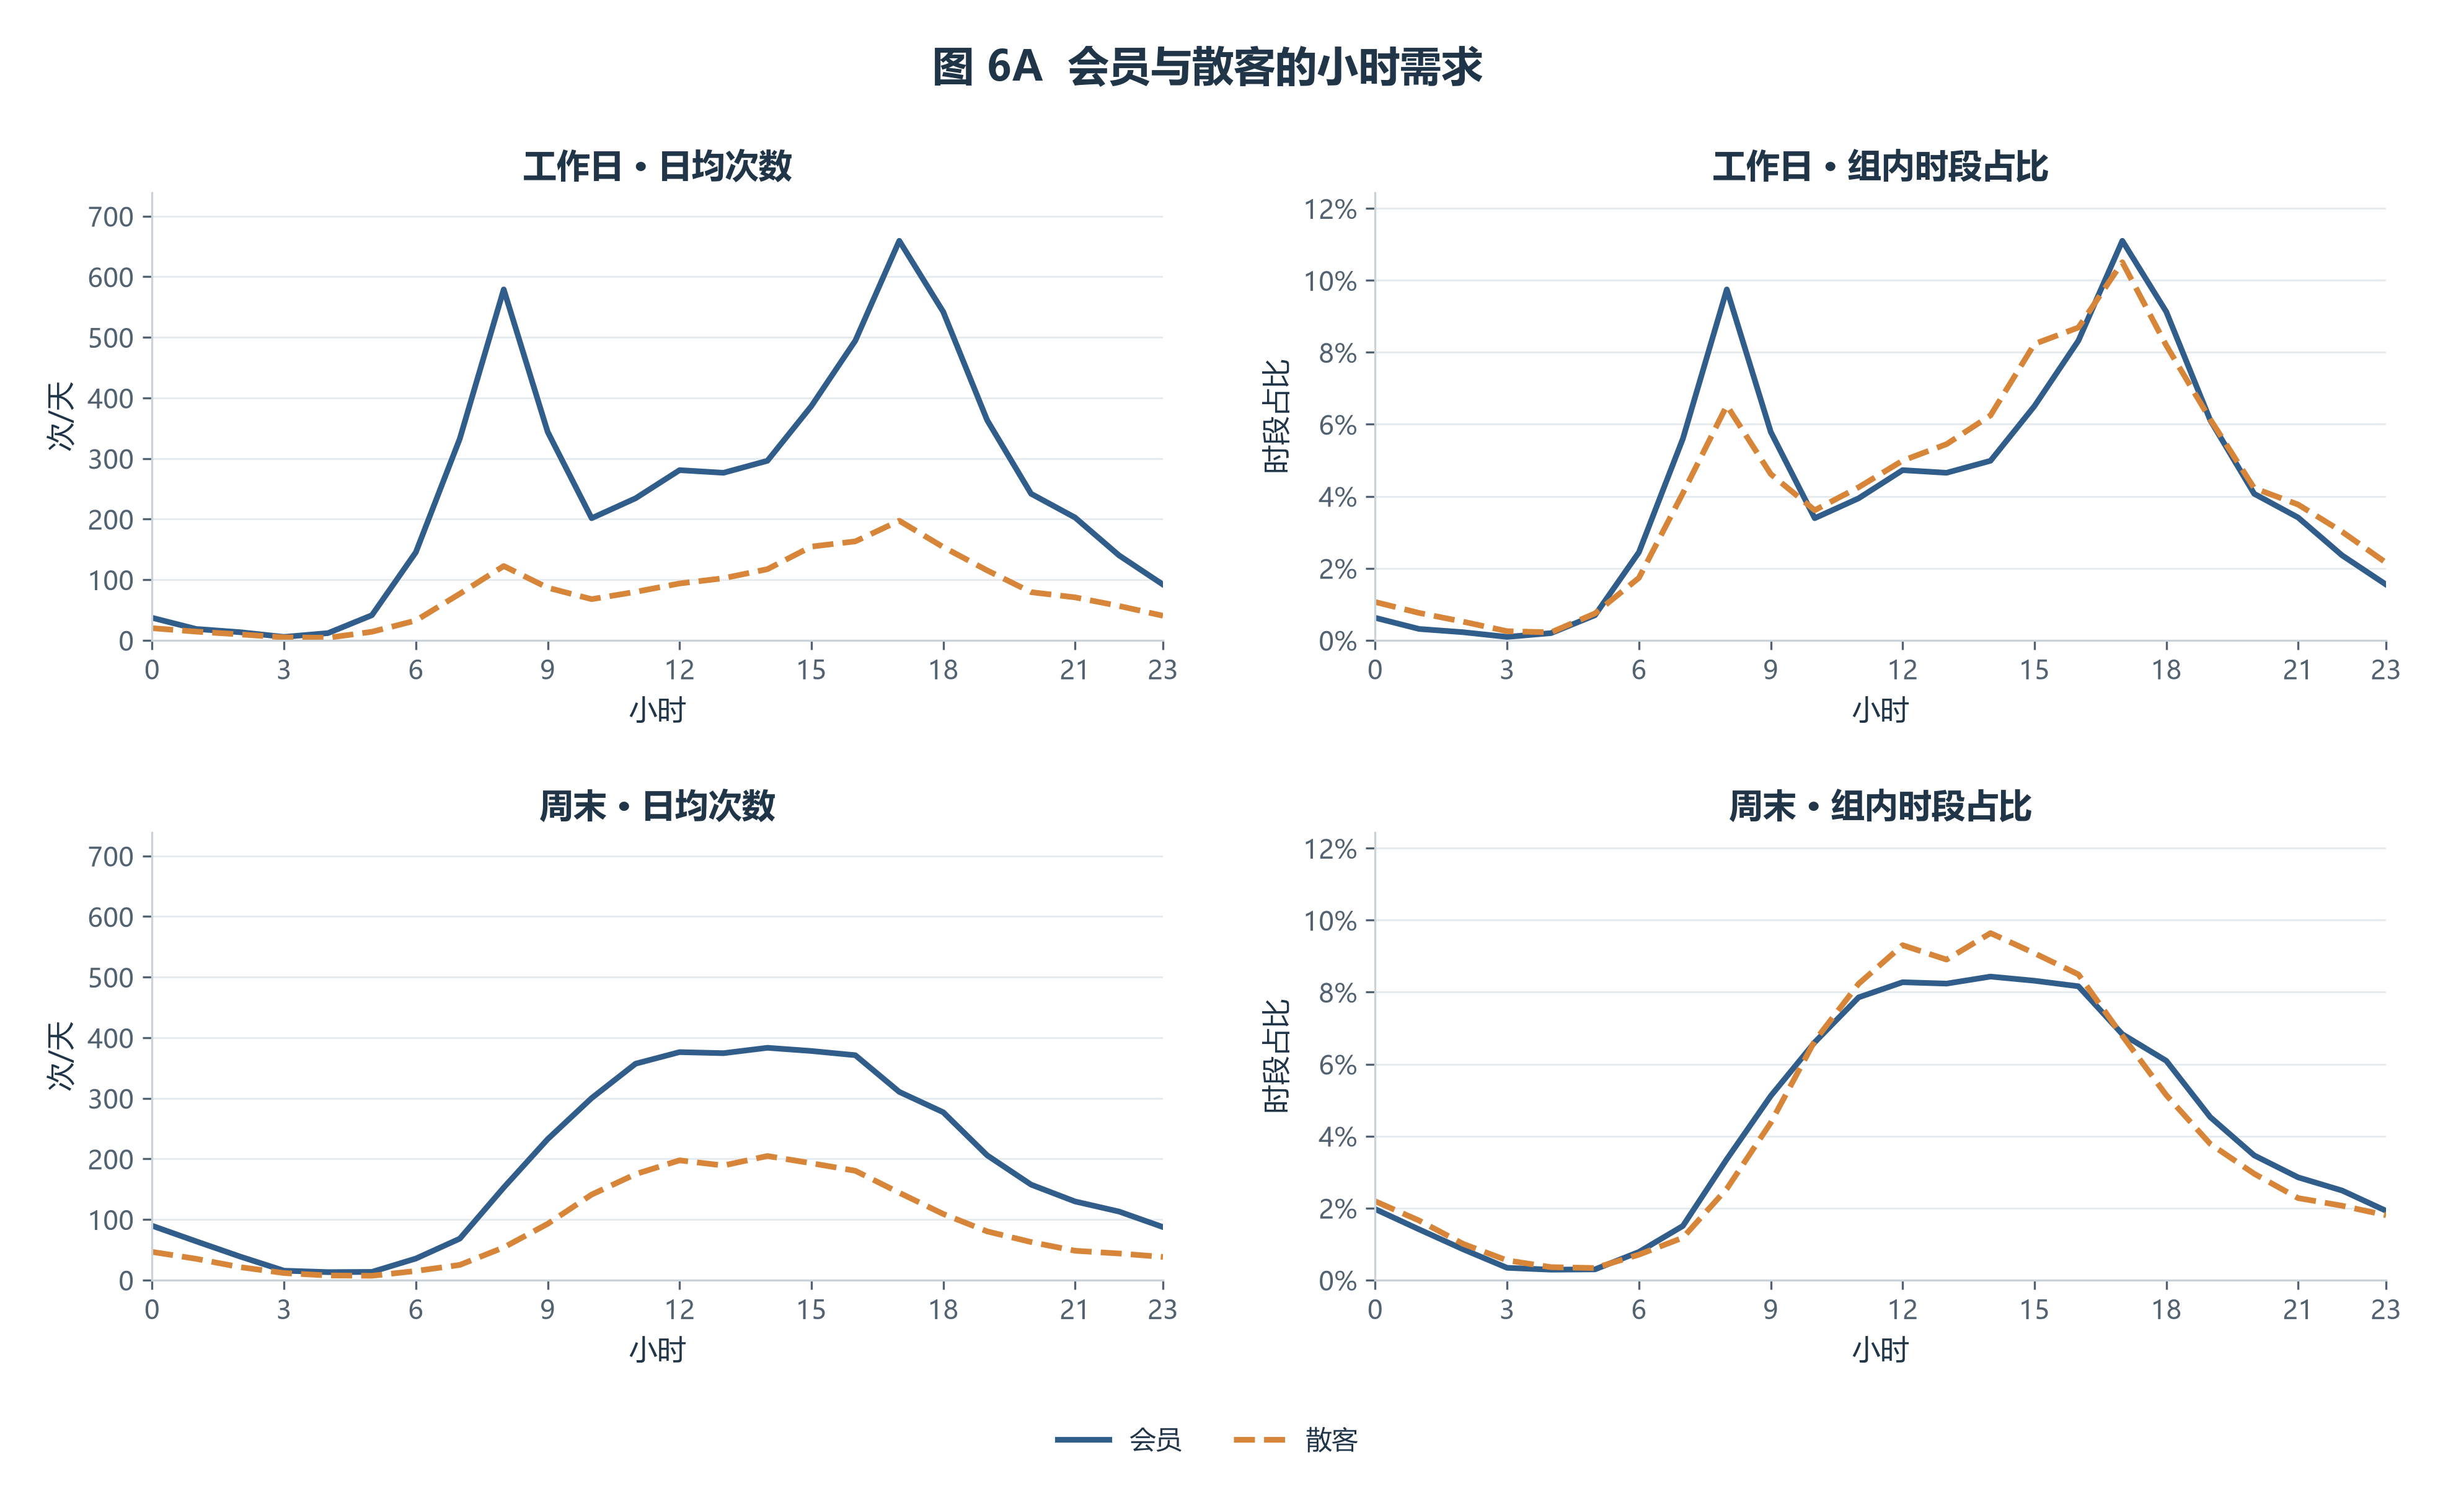

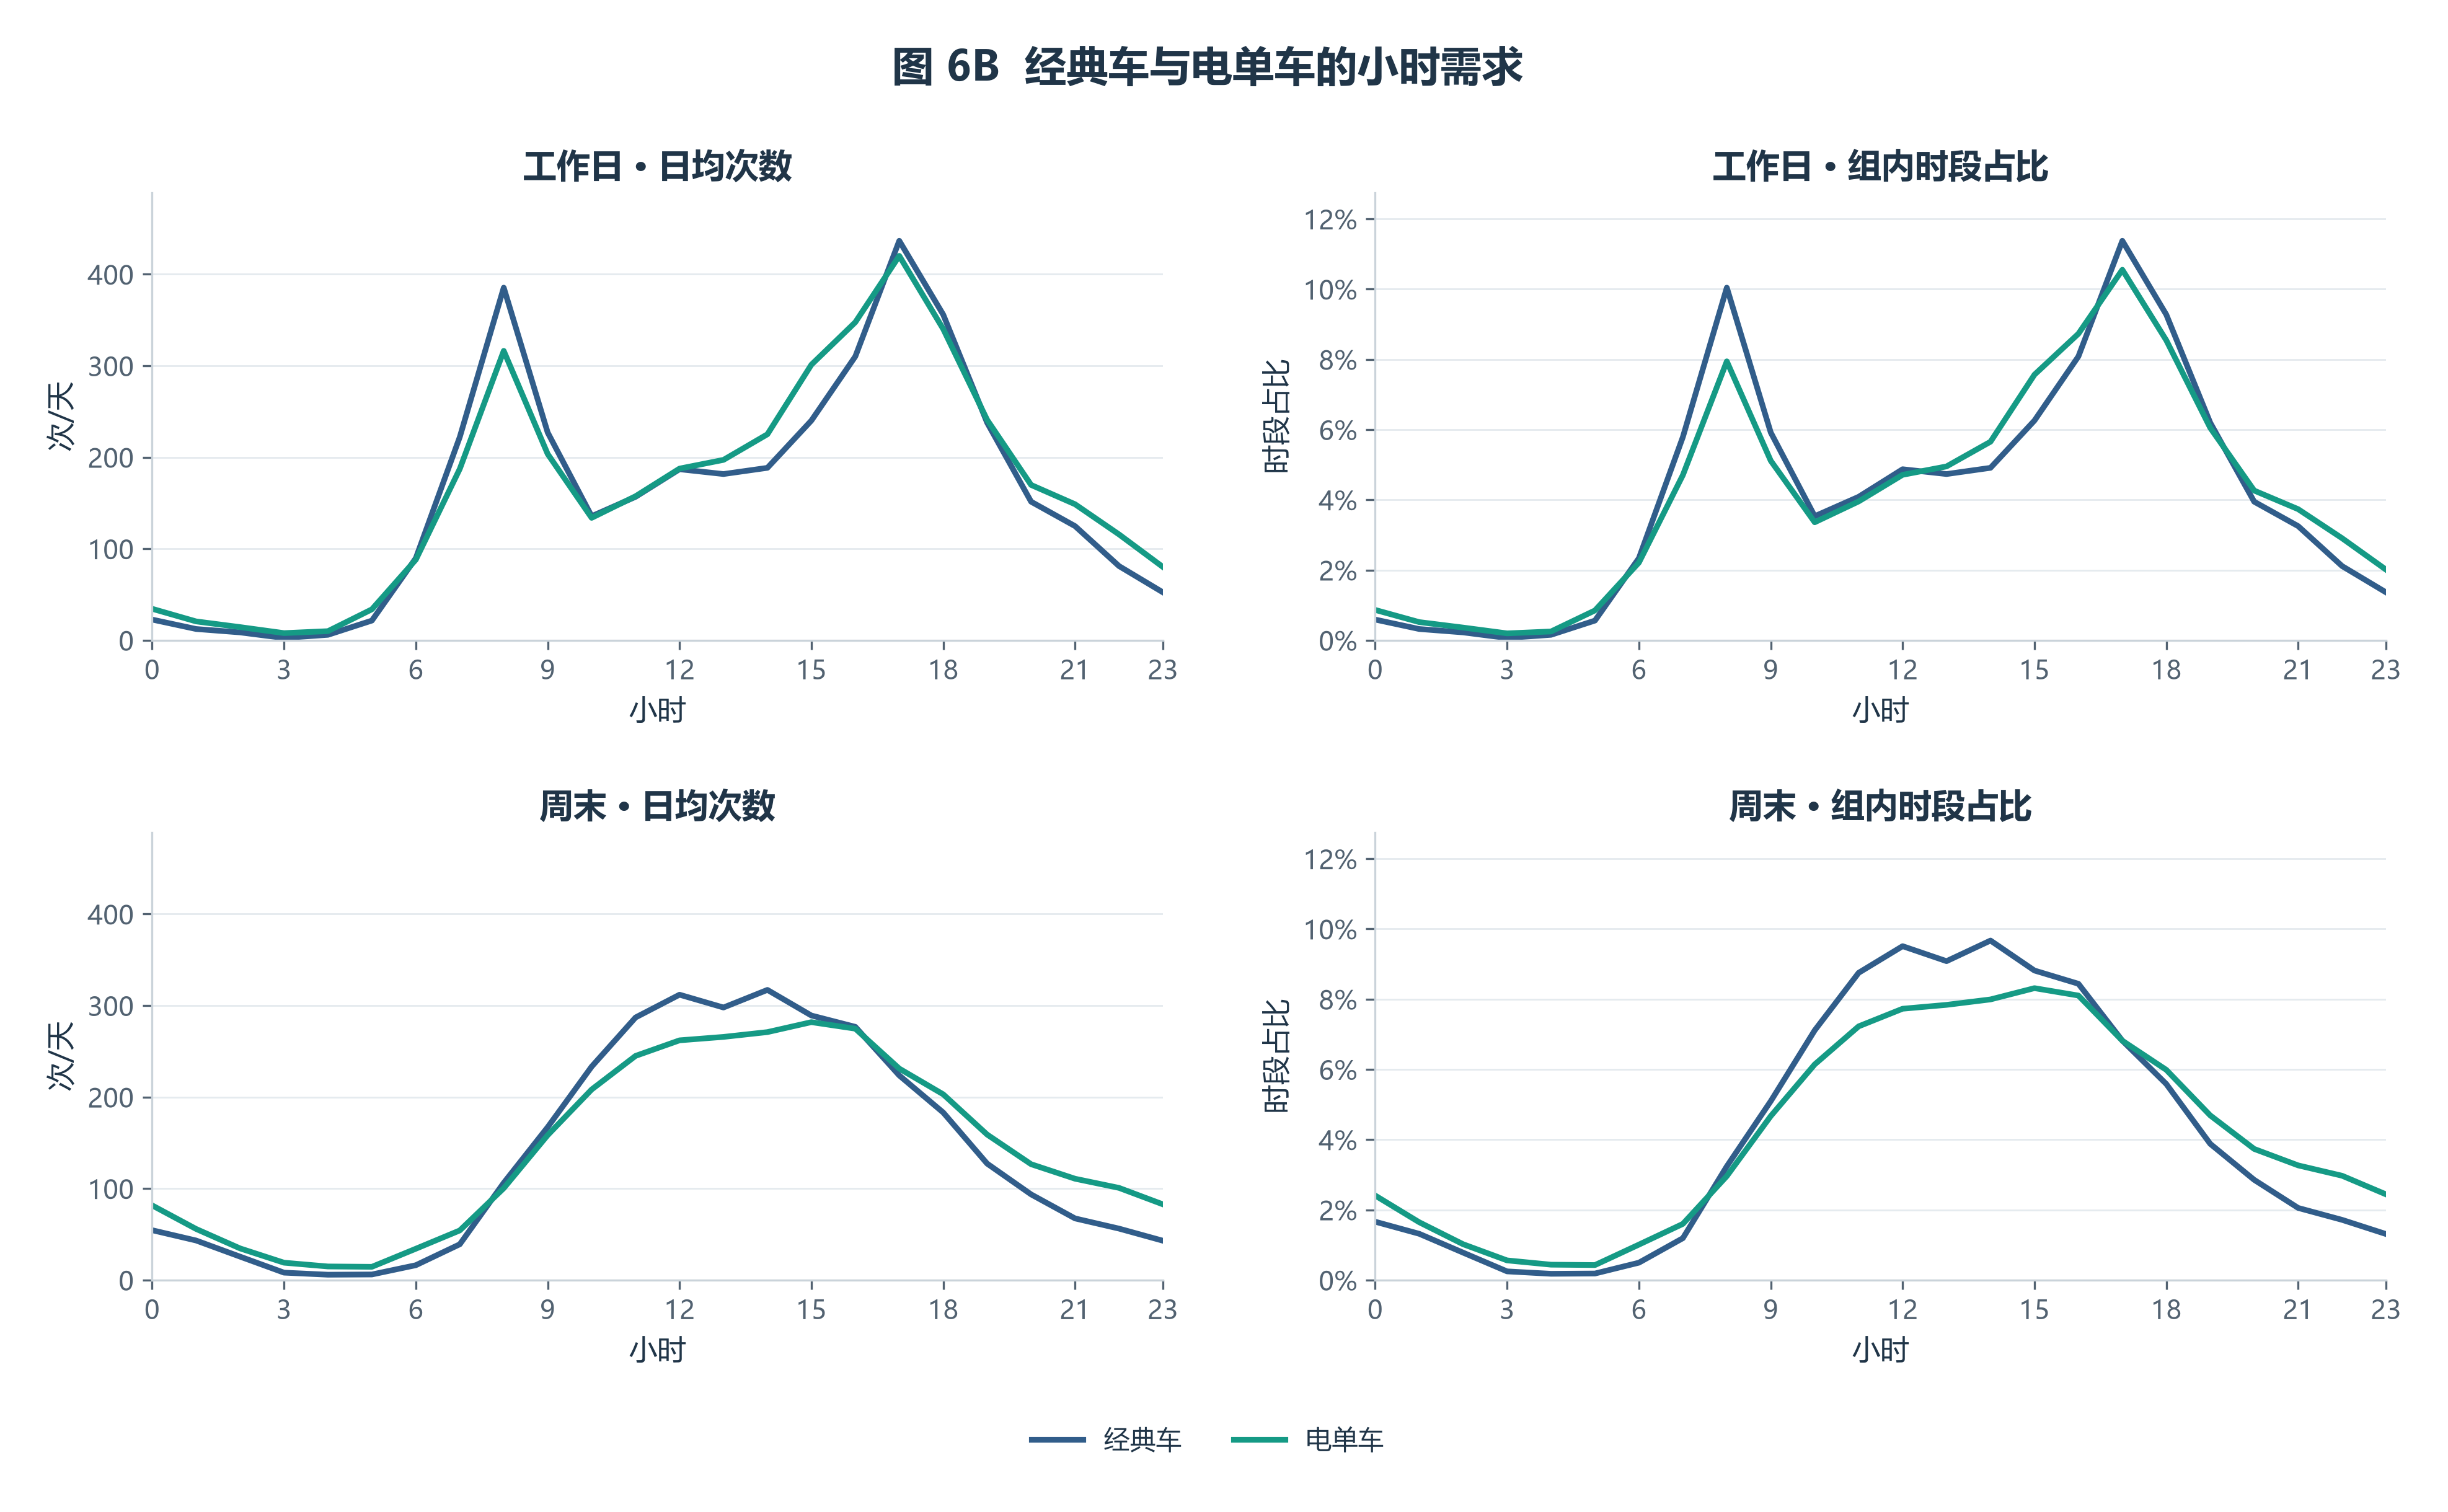

,dimension,day_type,group,total_rides,days,daily_mean_total,peak_hours,peak_daily_mean,peak_time_share
0,会员类型,工作日,会员,136621,23,5940.043478,17,659.347826,0.111001
1,会员类型,工作日,散客,43200,23,1878.260870,17,197.304348,0.105046
2,会员类型,周末,会员,36369,8,4546.125000,14,383.375000,0.084330
3,会员类型,周末,散客,16990,8,2123.750000,14,204.750000,0.096410
4,车辆类型,工作日,经典车,88254,23,3837.130435,17,436.565217,0.113774
5,车辆类型,工作日,电单车,91567,23,3981.173913,17,420.086957,0.105518
6,车辆类型,周末,经典车,26236,8,3279.500000,14,317.125000,0.096699
7,车辆类型,周末,电单车,27123,8,3390.375000,15,281.875000,0.083140
8,会员×车型,工作日,会员 · 经典车,69920,23,3040.000000,17,352.000000,0.115789
9,会员×车型,工作日,会员 · 电单车,66701,23,2900.043478,17,307.347826,0.105980


In [3]:
show_figure('fig04_workday_weekend_hourly.png')
show_figure('fig05_weekday_hour_heatmap.png')
show_figure('fig06a_membership_hourly.png')
show_figure('fig06b_vehicle_hourly.png')
display(pd.read_csv(TABLES / 'fig06_preference_summary.csv'))

## 2. 固定预测起点，避免把未来信息放进特征

验证：1 月 1–14 日训练、15–21 日验证；最终测试：1 月 1–21 日重训、22–28 日测试。
参数与推荐模型在验证后冻结。1 月 29–31 日保留在数据中，但不参加本轮评价。

预测周内不更新实际需求。周滞后特征 `lag_168h` 来自起点之前一周；小时、星期与周期特征
来自已知日历。学习模型需要周滞后，因此有效训练样本比原始小时数少。

In [4]:
origin, end = PHASES['test']
history = y.loc[y.index < origin]
future_index = pd.date_range(origin, end, freq='h', inclusive='left')
design = features(history, future_index, forecast_origin=origin)
assert history.index.max() < origin
assert (future_index - pd.Timedelta(hours=168) < origin).all()
assert len(design) == 168 and not design.isna().any().any()
display(design.head())
print('最终测试特征只使用预测起点之前的历史。')

,hour_sin_24,hour_cos_24,hour_sin_12,hour_cos_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,is_weekend,weekend_x_hour_sin_24,weekend_x_hour_cos_24,weekend_x_hour_sin_12,weekend_x_hour_cos_12,lag_168h
2024-01-22 00:00:00,0.000000,1.000000,0.000000,1.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.0
2024-01-22 01:00:00,0.258819,0.965926,0.500000,8.660254e-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.0
2024-01-22 02:00:00,0.500000,0.866025,0.866025,5.000000e-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.0
2024-01-22 03:00:00,0.707107,0.707107,1.000000,6.123234e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.0
2024-01-22 04:00:00,0.866025,0.500000,0.866025,-5.000000e-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,12.0


最终测试特征只使用预测起点之前的历史。


## 3. 全城小时需求预测

比较历史同期均值、上周同期、Ridge 与随机森林。历史均值、Ridge、随机森林参与验证选型，
上周同期作为补充对照。MAE 与 RMSE 是次数误差，R² 不是准确率。

demand_model：重新计算与导出完成。
验证后冻结推荐： historical_mean


,phase,model,recommended_frozen,history_hours,fit_rows,negative_raw_predictions,mae,rmse,r2,peak_mae,total_actual,total_predicted,total_bias
0,validation,historical_mean,True,336,336,0,156.619048,215.449813,-1.222544,395.464286,27778.0,54072.000000,26294.000000
1,validation,last_week,False,336,336,0,199.654762,283.703400,-2.853782,519.142857,27778.0,59318.000000,31540.000000
2,validation,ridge,False,336,168,4,209.430691,250.326062,-2.000338,309.924831,27778.0,62797.733959,35019.733959
3,validation,random_forest,False,336,168,0,205.190915,253.867012,-2.085820,315.533847,27778.0,61709.130722,33931.130722
4,test,historical_mean,True,504,504,0,144.148810,234.920750,0.509586,330.642857,67307.0,45307.333333,-21999.666667
5,test,last_week,False,504,504,0,237.672619,346.749987,-0.068446,577.285714,67307.0,27778.000000,-39529.000000
6,test,ridge,False,504,336,4,192.487604,291.890902,0.242887,543.956918,67307.0,40211.880197,-27095.119803
7,test,random_forest,False,504,336,0,176.663605,276.377833,0.321224,509.044909,67307.0,39943.841402,-27363.158598


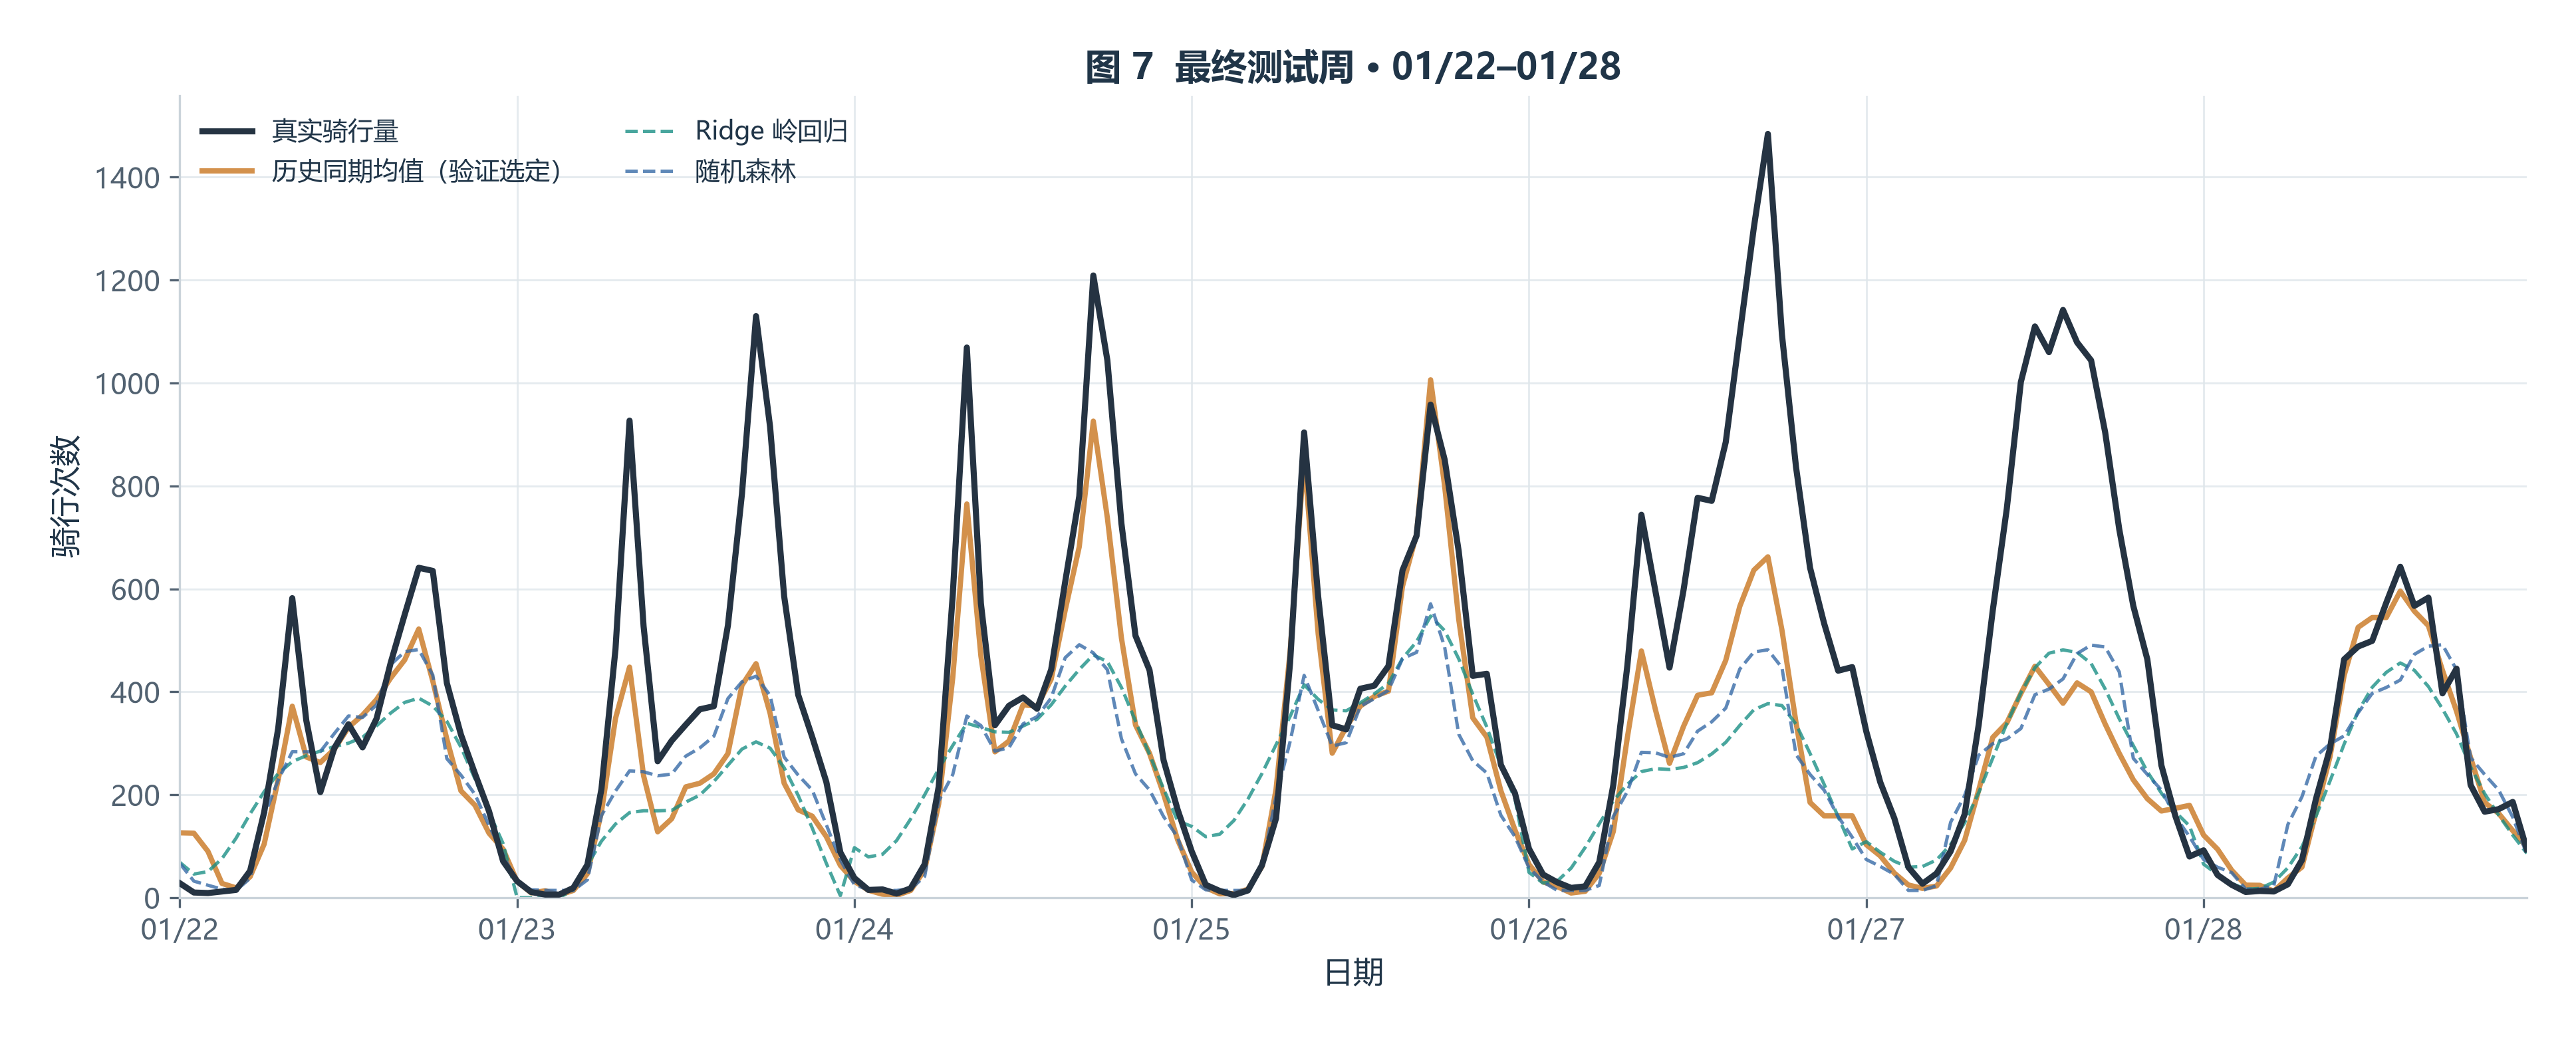

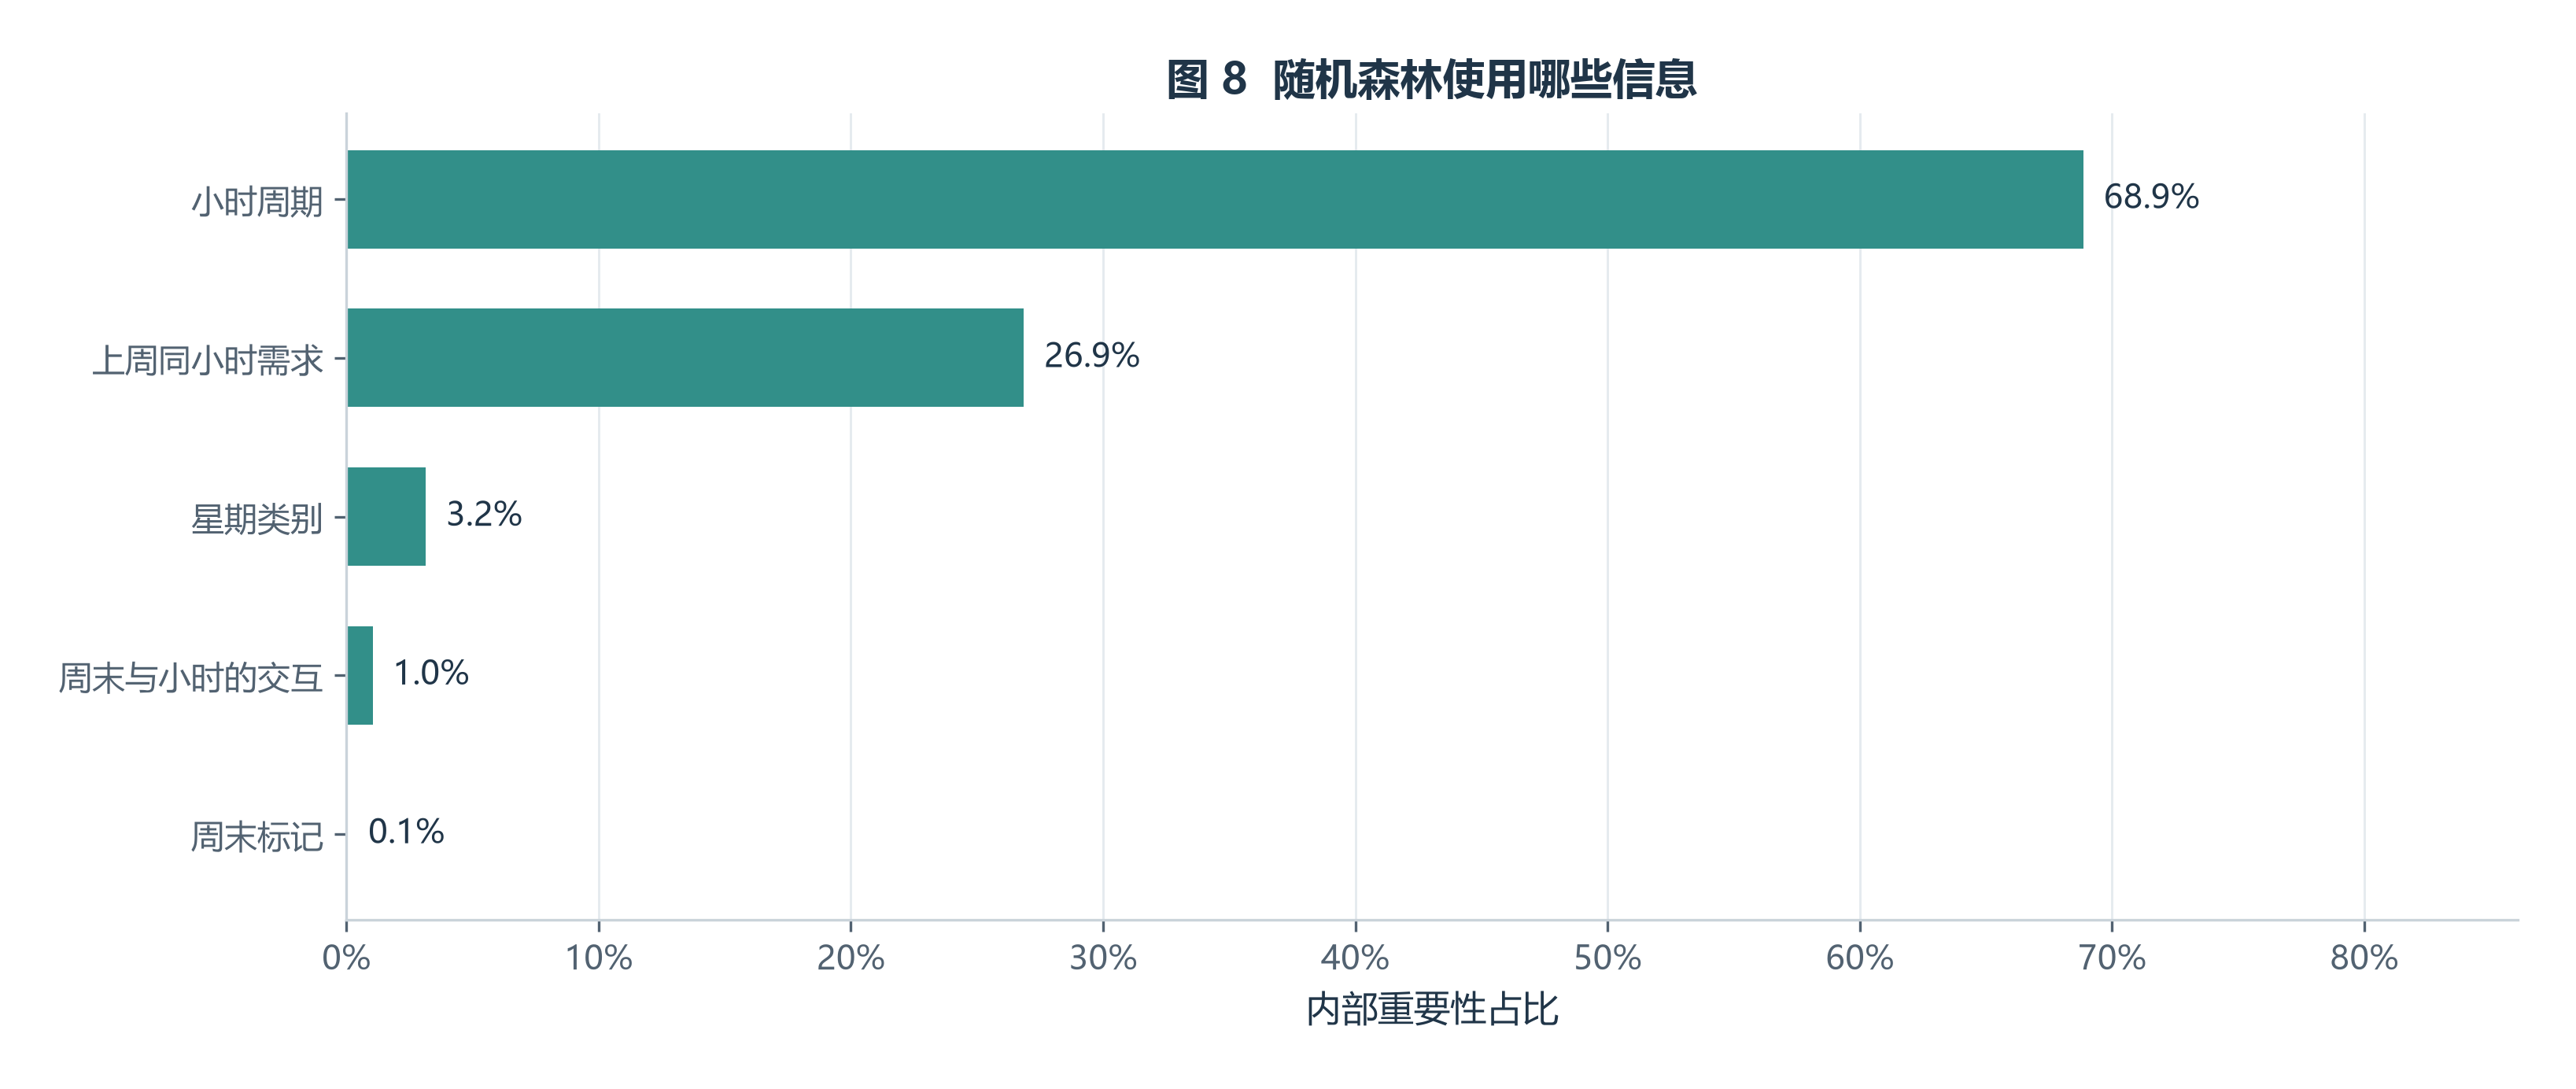

In [5]:
run_module('demand_model')
city_selection = json.loads((TABLES / 'city_model_selection.json').read_text(encoding='utf-8'))
city_metrics = pd.read_csv(TABLES / 'city_model_metrics.csv')
city_checks = pd.read_csv(TABLES / 'city_prediction_validation.csv')
assert city_checks.passed.all()
print('验证后冻结推荐：', city_selection['recommended_model'])
display(city_metrics)
show_figure('fig07_city_weekly_prediction.png')
show_figure('fig08_city_feature_importance.png')

## 4. 核心站点的借出、归还与净流出

站点预测按已知端点分别保留事件，归还按 `ended_at` 统计。Top10 只用前两周筛选并冻结，
不使用整月空间排行挑选测试对象。月初三个小时可能缺少前月出发订单的归还，按未知处理。

模型在 10 个站点间共享，借出、归还分别拟合，再相减得到净流出。
净流出有正负，不能解释为库存、实际缺车数或未满足需求。

In [6]:
run_module('station_model')
station_selection = json.loads((TABLES / 'station_model_selection.json').read_text(encoding='utf-8'))
selected = pd.read_csv(TABLES / 'station_top10.csv', dtype={'station_id': 'string'})
station_metrics = pd.read_csv(TABLES / 'station_overall_metrics.csv')
station_checks = pd.read_csv(TABLES / 'station_prediction_validation.csv')
assert selected.station_id.nunique() == 10 and station_checks.passed.all()
print('验证后冻结推荐：', station_selection['recommended_model'])
display(selected[['selection_rank', 'station_id', 'station_name', 'tidal_score']])
display(station_metrics.loc[station_metrics.phase.eq('test')])

station_model：重新计算与导出完成。
验证后冻结推荐： historical_mean


,selection_rank,station_id,station_name,tidal_score
0,1,31623,Columbus Circle / Union Station,36.944444
1,2,31101,14th & V St NW,29.595238
2,3,31229,New Hampshire Ave & T St NW,29.238095
3,4,31233,17th & K St NW / Farragut Square,27.952381
4,5,31232,7th & F St NW / National Portrait Gallery,25.738095
5,6,31277,17th & G St NW,25.658730
6,7,31102,11th & Kenyon St NW,23.587302
7,8,31202,14th & R St NW,23.460317
8,9,31613,Eastern Market Metro / Pennsylvania Ave & 8th ...,23.023810
9,10,31640,Maryland Ave & E St NE,22.674603


,phase,model,target,mean_station_mae,pooled_rmse,mean_station_peak_mae,total_actual,total_predicted,total_bias
12,test,historical_mean,outflow,1.526984,2.516795,3.133333,4348.0,2968.000000,-1380.000000
13,test,historical_mean,inflow,1.499802,2.545154,3.695238,4349.0,2961.000000,-1388.000000
14,test,historical_mean,net_outflow,1.692460,2.581355,3.016667,-1.0,7.000000,8.000000
15,test,last_week,outflow,1.945238,3.279990,4.585714,4348.0,1890.000000,-2458.000000
16,test,last_week,inflow,1.908929,3.395638,5.550000,4349.0,1874.000000,-2475.000000
17,test,last_week,net_outflow,1.876786,2.974395,4.121429,-1.0,16.000000,17.000000
18,test,ridge,outflow,1.760066,2.968803,4.396301,4348.0,2608.331041,-1739.668959
19,test,ridge,inflow,1.826262,3.218850,5.662423,4349.0,2441.795460,-1907.204540
20,test,ridge,net_outflow,1.813135,2.915681,4.528284,-1.0,166.535581,167.535581
21,test,random_forest,outflow,1.769136,3.047845,4.372836,4348.0,2506.591982,-1841.408018


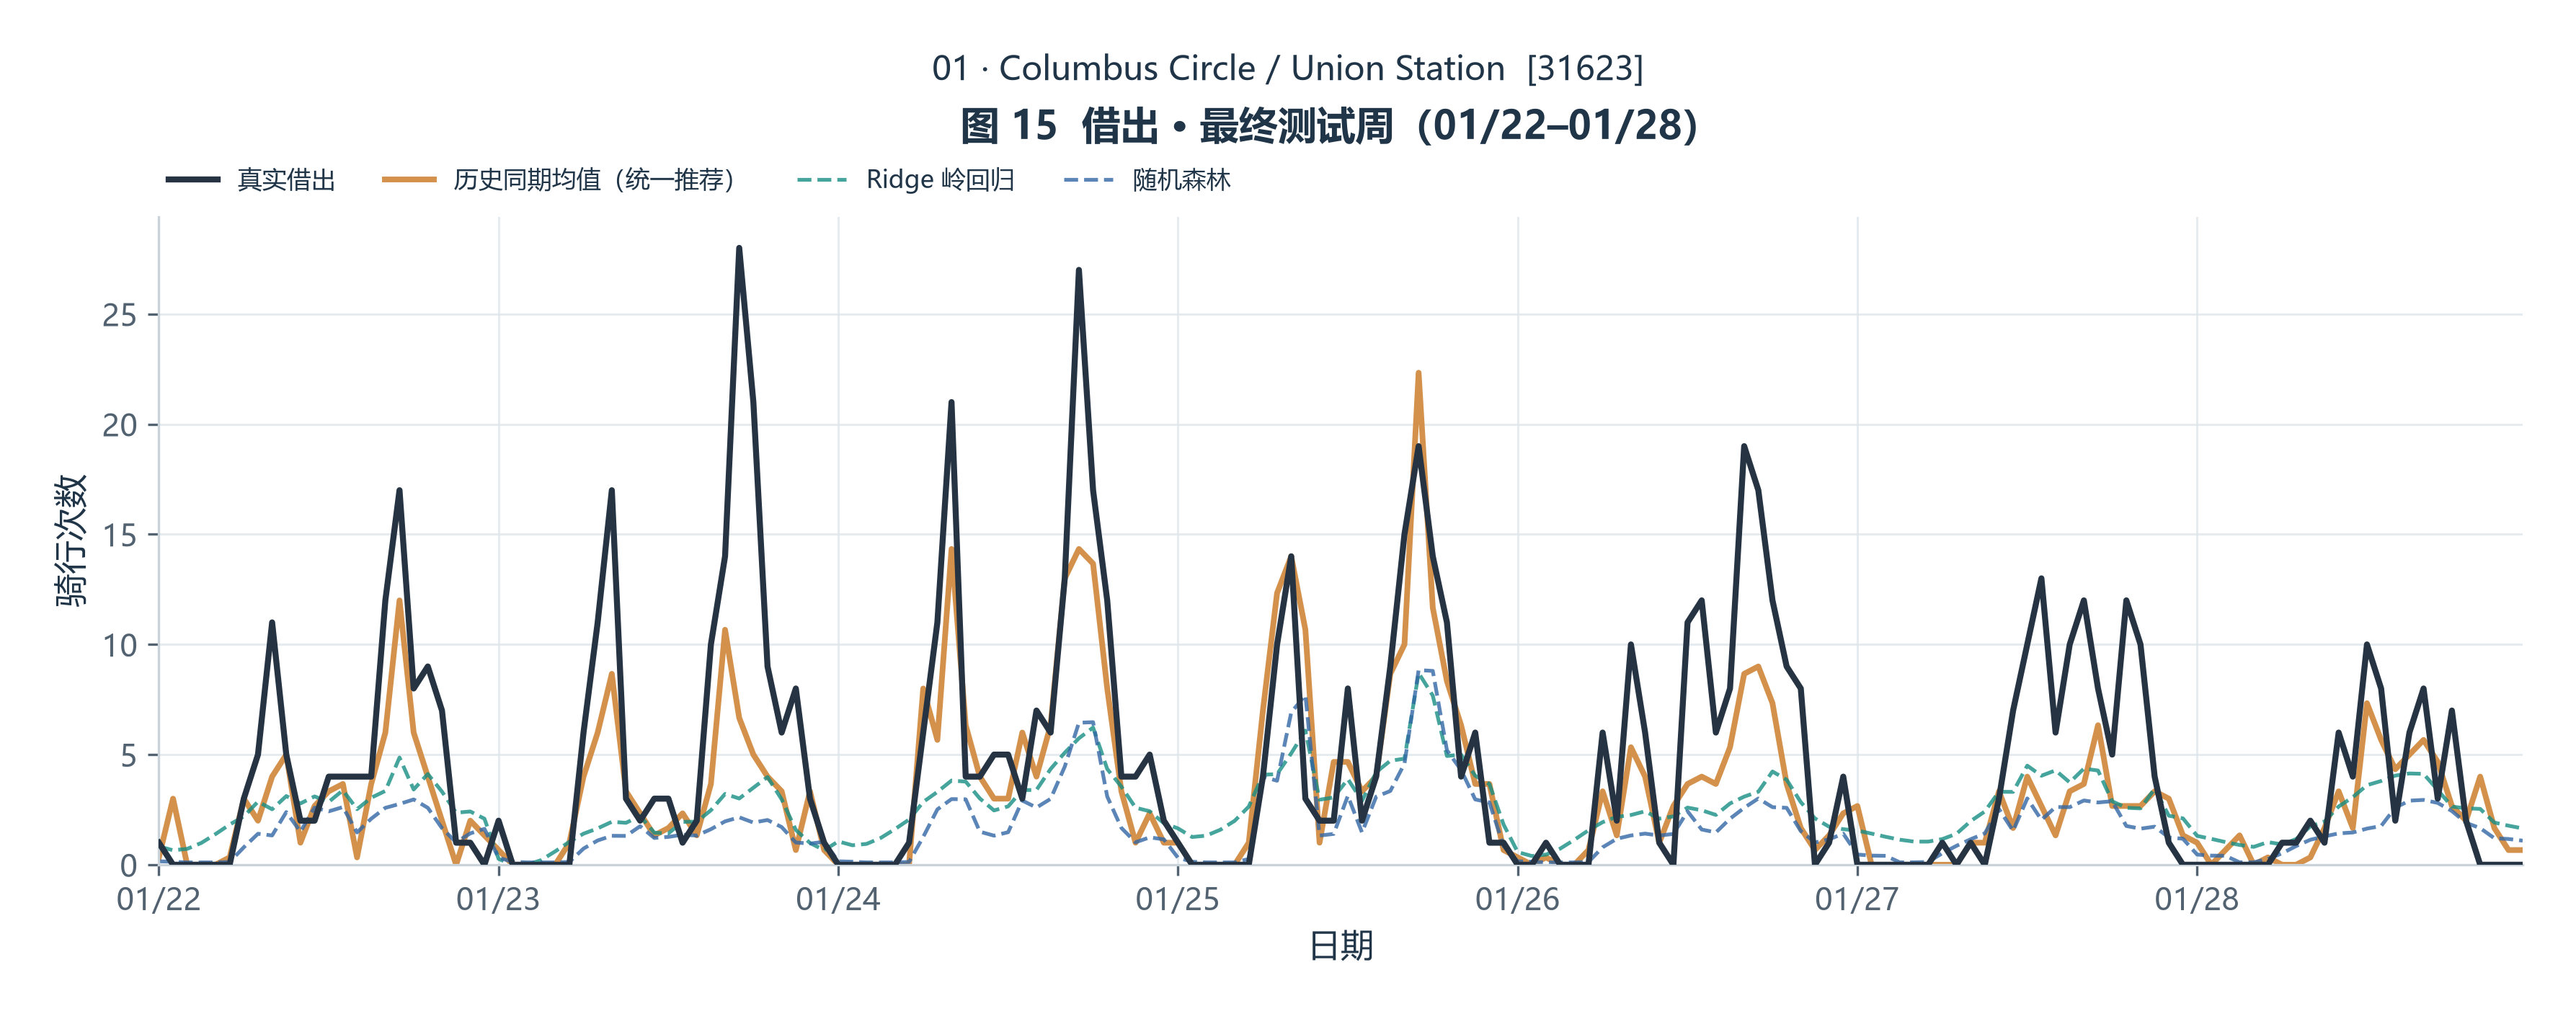

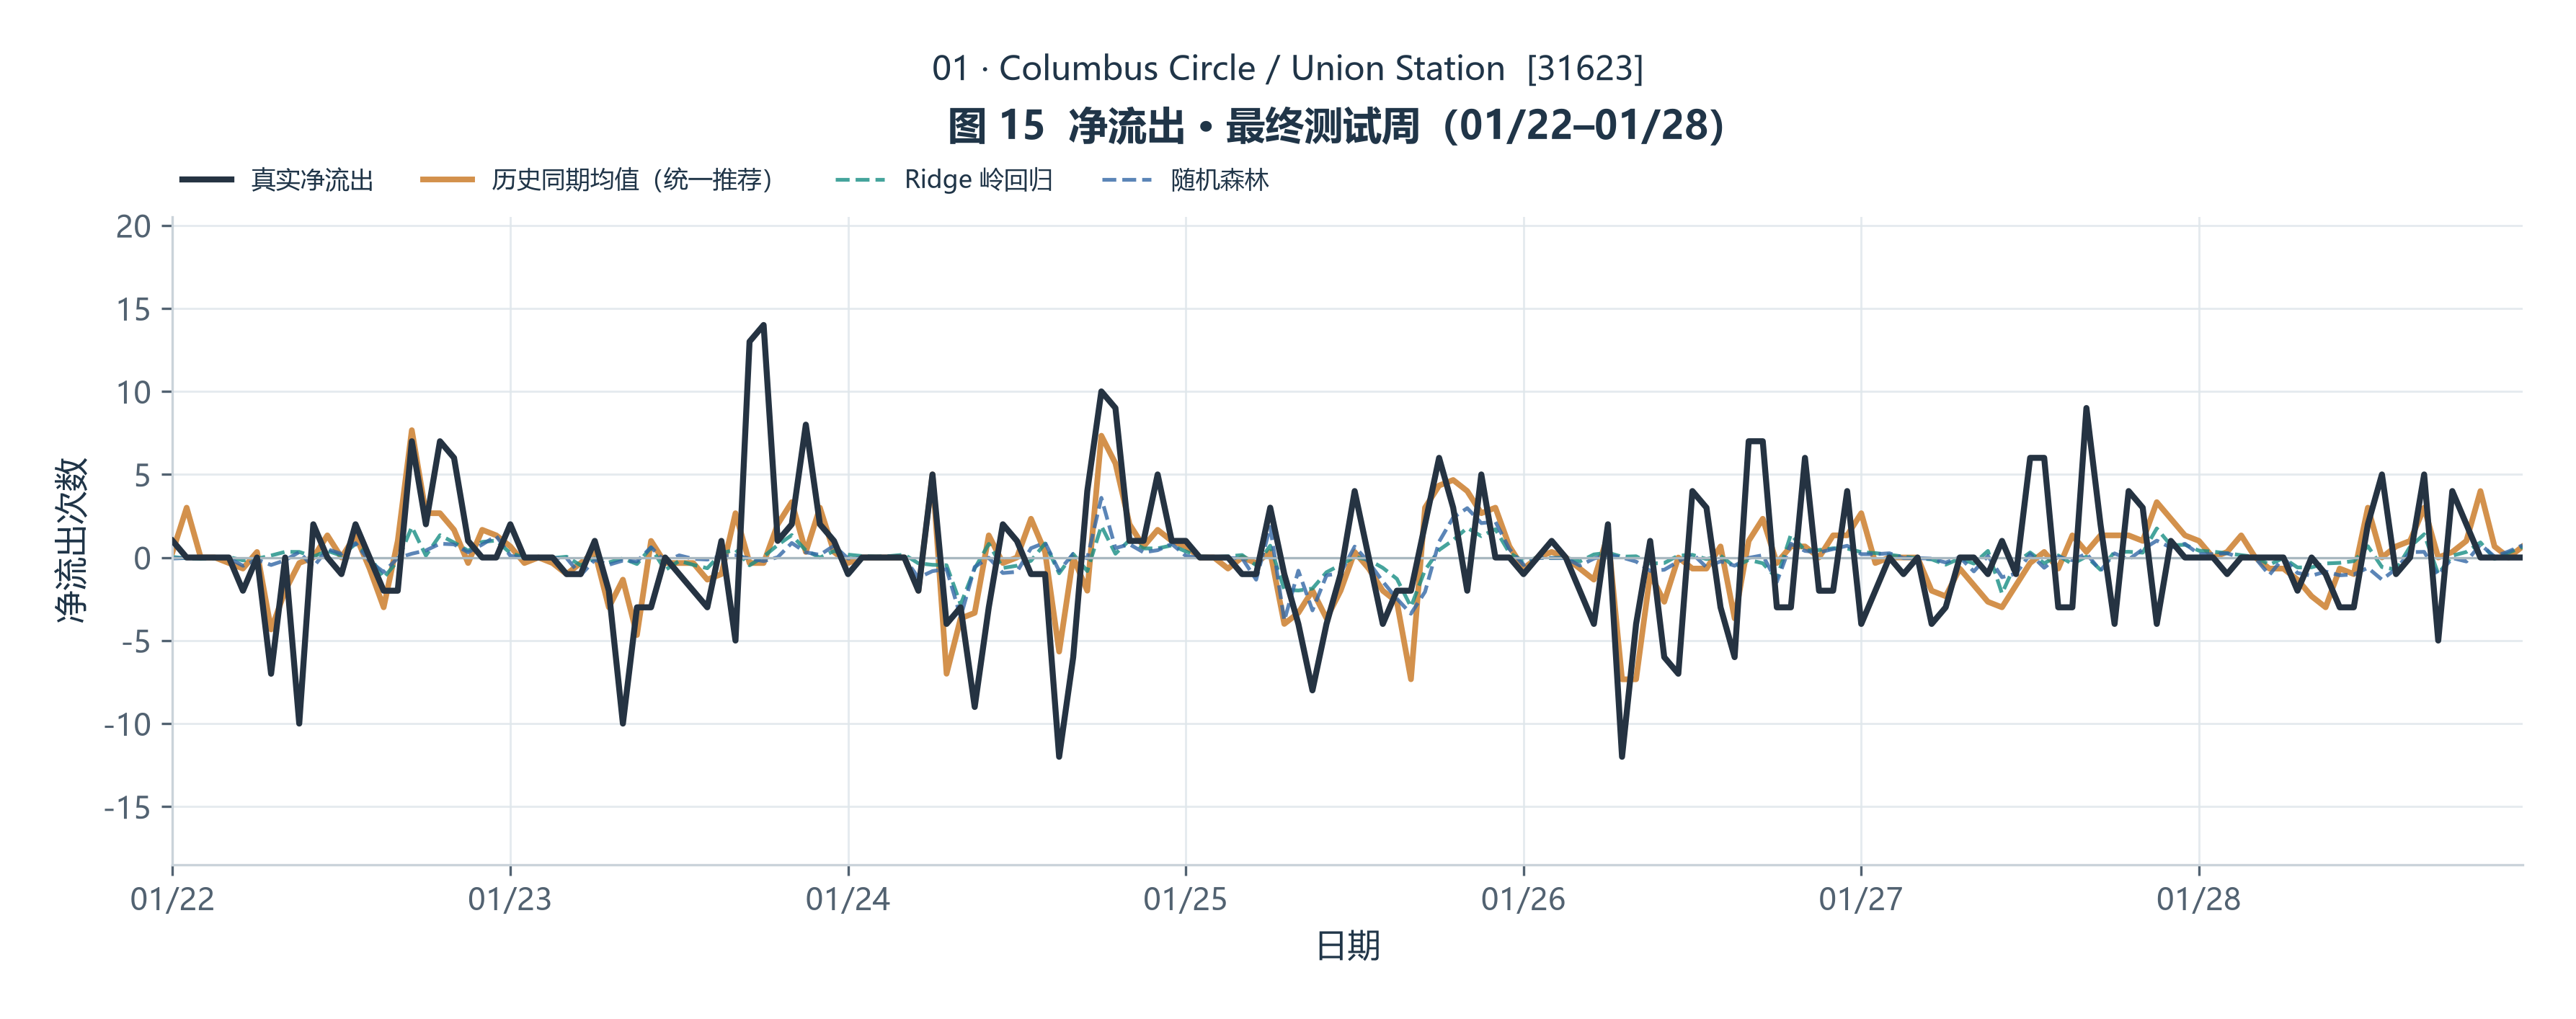

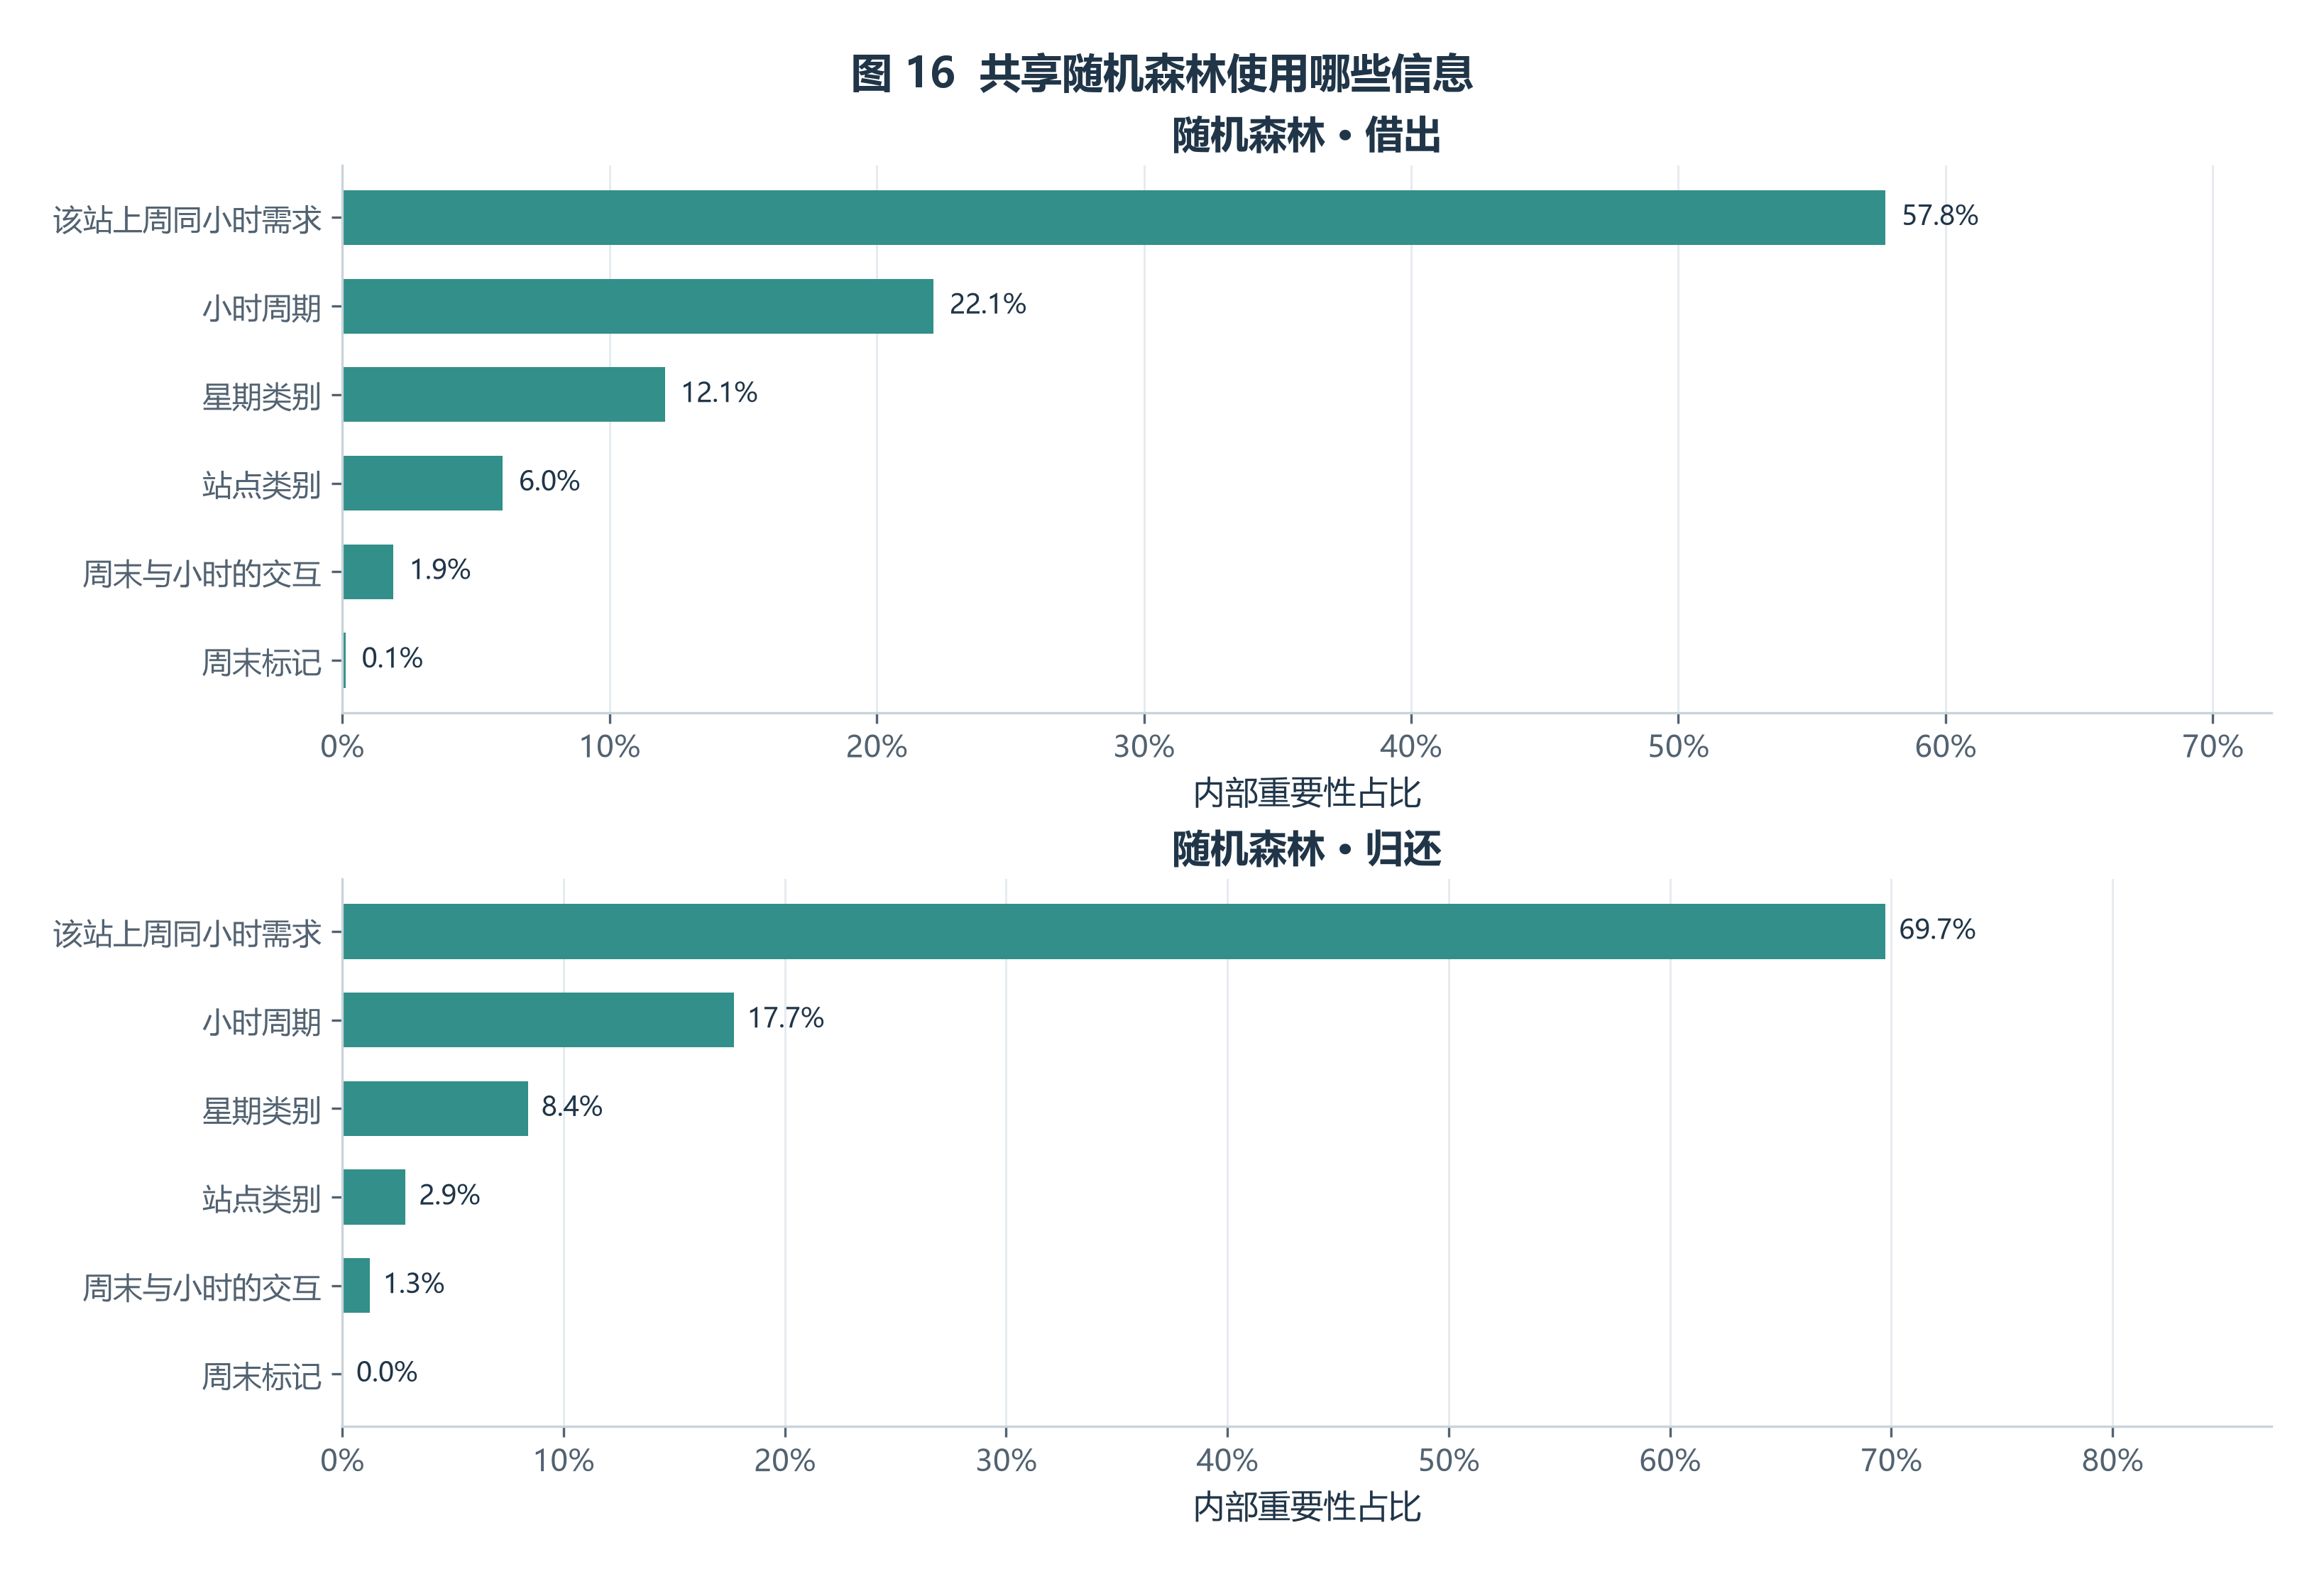

In [7]:
rank = int(selected.iloc[0].selection_rank)
show_figure(f'stations/station_{rank:02d}_outflow_test.png')
show_figure(f'stations/station_{rank:02d}_net_outflow_test.png')
show_figure('fig16_station_feature_importance.png')

## 5. 统一比较与误差复核

比较模块只读取已保存的预测重新计算指标，不重新训练或在测试结果上选模型。
全城与站点目标规模不同，分别评价；站点总体 MAE 是逐站 MAE 平均，不能用全城误差作横向排名。
随机森林特征重要性只说明模型内部的权重分配，不能解释因果。

model_comparison：重新计算与导出完成。
预测表与指标一致性核验通过： 230


,phase,scope,target,model,mae,rmse,r2,peak_mae,total_actual,total_predicted,total_bias,recommended_frozen,mae_label,rmse_label,bias_pct
4,test,city,city_demand,historical_mean,144.148810,234.920750,0.509586,330.642857,67307.0,45307.333333,-21999.666667,True,MAE,RMSE,-32.685555
5,test,city,city_demand,last_week,237.672619,346.749987,-0.068446,577.285714,67307.0,27778.000000,-39529.000000,False,MAE,RMSE,-58.729404
6,test,city,city_demand,ridge,192.487604,291.890902,0.242887,543.956918,67307.0,40211.880197,-27095.119803,False,MAE,RMSE,-40.256021
7,test,city,city_demand,random_forest,176.663605,276.377833,0.321224,509.044909,67307.0,39943.841402,-27363.158598,False,MAE,RMSE,-40.654254
20,test,station,outflow,historical_mean,1.526984,2.516795,NaN,3.133333,4348.0,2968.000000,-1380.000000,True,各站 MAE 平均值,合并 RMSE,-31.738730
21,test,station,inflow,historical_mean,1.499802,2.545154,NaN,3.695238,4349.0,2961.000000,-1388.000000,True,各站 MAE 平均值,合并 RMSE,-31.915383
22,test,station,net_outflow,historical_mean,1.692460,2.581355,NaN,3.016667,-1.0,7.000000,8.000000,True,各站 MAE 平均值,合并 RMSE,NaN
23,test,station,outflow,last_week,1.945238,3.279990,NaN,4.585714,4348.0,1890.000000,-2458.000000,False,各站 MAE 平均值,合并 RMSE,-56.531739
24,test,station,inflow,last_week,1.908929,3.395638,NaN,5.550000,4349.0,1874.000000,-2475.000000,False,各站 MAE 平均值,合并 RMSE,-56.909634
25,test,station,net_outflow,last_week,1.876786,2.974395,NaN,4.121429,-1.0,16.000000,17.000000,False,各站 MAE 平均值,合并 RMSE,NaN


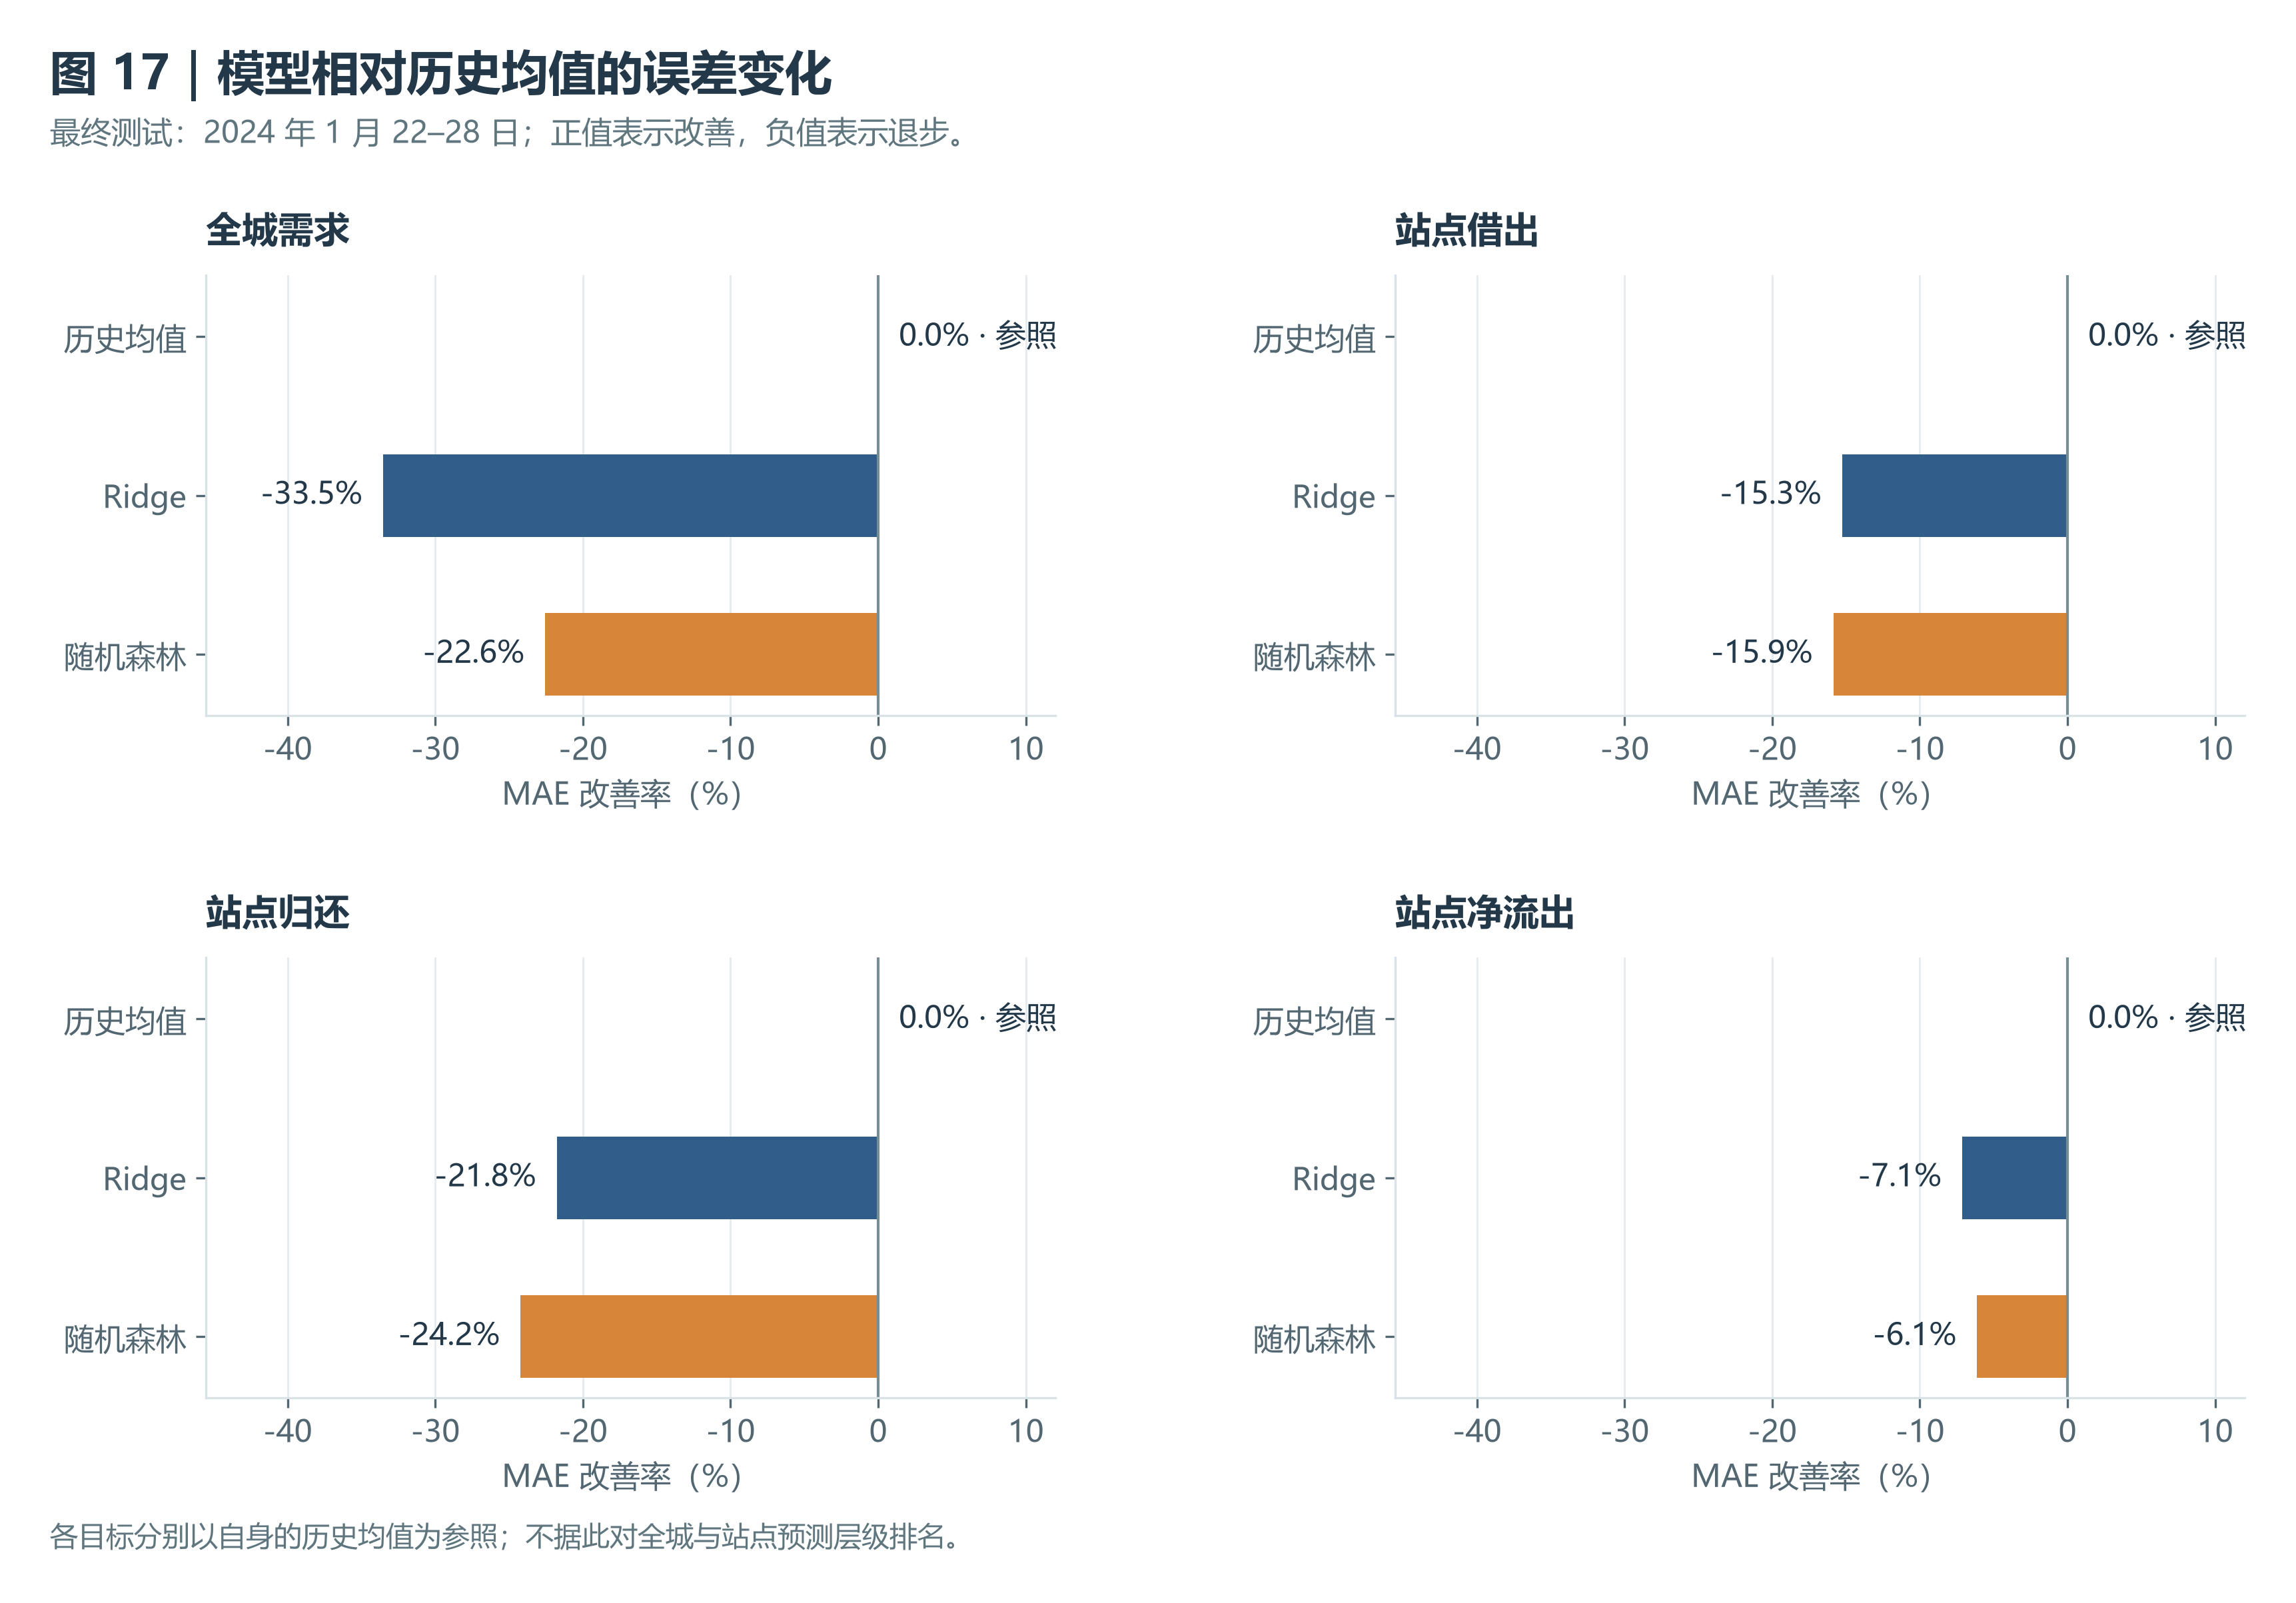

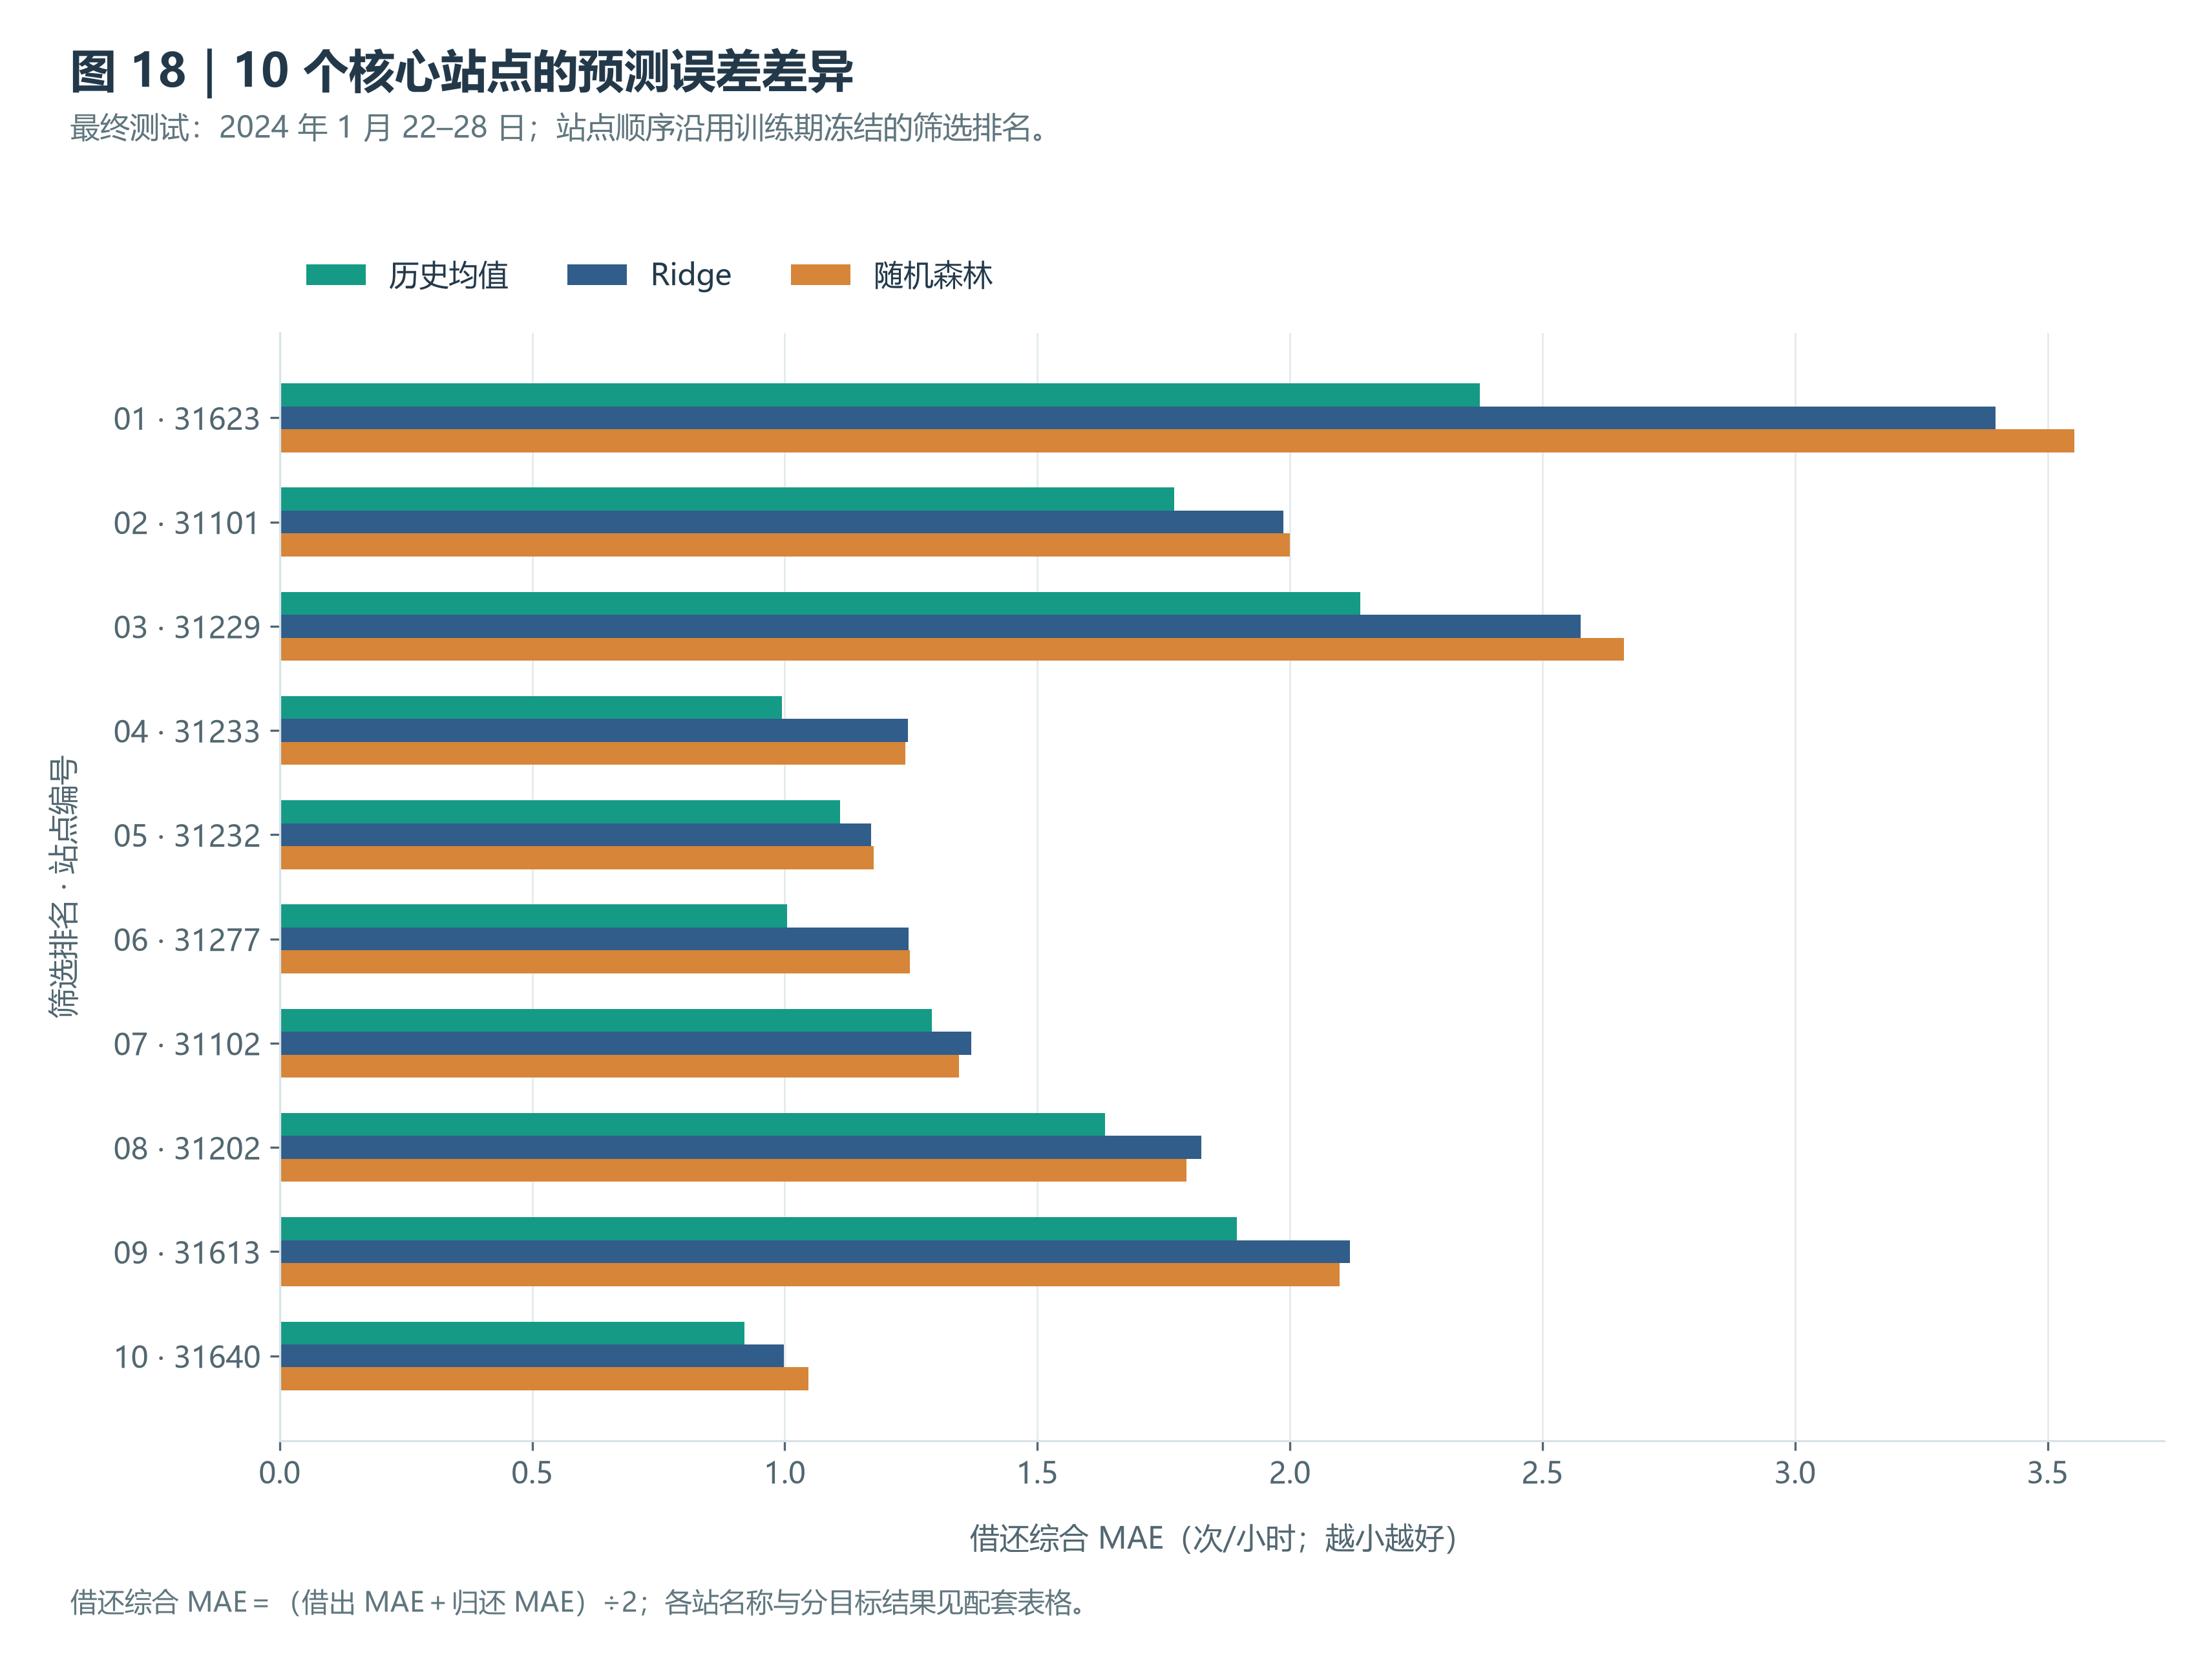

In [8]:
run_module('model_comparison')
comparison = json.loads((TABLES / 'model_comparison_checks.json').read_text(encoding='utf-8'))
checks = comparison['checks'] if isinstance(comparison, dict) else comparison
assert all(c['passed'] for c in checks)
print('预测表与指标一致性核验通过：', len(checks))
comparison_summary = pd.read_csv(TABLES / 'model_comparison_summary.csv')
display(comparison_summary.loc[comparison_summary.phase.eq('test')])
show_figure('fig17_model_comparison.png')
show_figure('fig18_station_error_comparison.png')

## 6. 输入、代码与结论边界

下方复核预测记录的输入和代码指纹，确认结果对应当前项目文件。预测模型与数据只覆盖单月，
只有一轮验证周与测试周；对这组数据的表现不代表其他月份或真实部署表现。

In [9]:
for module, selection in [('demand_model', city_selection), ('station_model', station_selection)]:
    provenance = selection['provenance']
    assert provenance['input_sha256'] == hashlib.sha256(source.read_bytes()).hexdigest()
    assert provenance['code_sha256'] == hashlib.sha256((ROOT / f'src/{module}.py').read_bytes()).hexdigest()
assert hashlib.sha256(source.read_bytes()).hexdigest() == original_hash
best_city = city_metrics.loc[city_metrics.phase.eq('test') &
                             city_metrics.model.eq(city_selection['recommended_model'])].iloc[0]
display(Markdown(
    f"本次全城冻结推荐为 **{city_selection['recommended_model']}**，测试 MAE 为 **{best_city.mae:.2f} 次/小时**；"
    f"站点冻结推荐为 **{station_selection['recommended_model']}**。推荐依据是验证结果，未按测试表现重选。"
    "输入文件未改动，全部预测与指标已重新生成。"))

本次全城冻结推荐为 **historical_mean**，测试 MAE 为 **144.15 次/小时**；站点冻结推荐为 **historical_mean**。推荐依据是验证结果，未按测试表现重选。输入文件未改动，全部预测与指标已重新生成。

## 7. 配套成果

- [时间与偏好报告](../reports/sections/02_temporal_and_prediction.md)
- [全城预测](../reports/sections/03_city_demand_prediction.md)
- [核心站点预测](../reports/sections/04_station_demand_prediction.md)
- [模型比较与误差分析](../reports/sections/05_model_comparison.md)
- [逐小时站点预测](../reports/tables/station_weekly_predictions.csv)

图1–14 沿用基础与空间分析编号；新增的站点预测、重要性与模型比较统一使用图15–18。
空间调度 Notebook 单独读取这里的预测结果；其历史情景不会反向改变这里的选型和评分。